# `csaps`'s 2-D tensor-product smoothing spline: mean decomposition and posterior variance

Notebook 1 confirmed that `csaps.CubicSmoothingSpline` (1-D) reproduces the
same cubic smoothing spline every other independently-written 1-D
implementation in this project does -- the direct motivation for this
notebook: does the same engine's 2-D, grid-based extension,
`csaps.NdGridCubicSmoothingSpline`, inherit that trustworthiness, and can a
posterior *variance* be derived for it the same way Notebook 1 derived one
for the 1-D case?

**Why this model first, among the N-D methods this project studies**: a
single smoothing penalty per axis ($p_1,p_2$, or $\lambda_1,\lambda_2$) is
structurally the closest tensor-product generalization of the
$\lambda$-penalized smoothing spline already proven in Notebook 1 -- a
cleaner first target than RMTB's composite basis-plus-energy-weight
structure (Notebooks 3 onward).

**References this notebook relies on** (published, not an internal draft):
de Boor (1978), *A Practical Guide to Splines* (the classical tensor-product
smoothing-spline algorithm `csaps` implements); the same Kimeldorf-Wahba
duality (1970) and Bayesian linear-Gaussian identity used throughout
Notebook 1.

## 1. Theoretical background

### 1.1 `csaps.NdGridCubicSmoothingSpline`: two sequential 1-D passes

Given a 2-D grid of response values $Z$ on a Cartesian grid
$x_1\times x_2$, `csaps`'s tensor-product smoothing spline fits by
**smoothing every row along $x_2$ first, then smoothing the resulting array
of row-fits along $x_1$** -- the classical de Boor algorithm. This is only
valid because the penalty separates into independent per-axis terms; it is
not automatic for an arbitrary 2-D smoother.

**In plain terms**: fit a 1-D smoothing spline along one direction for every
row of the data, then fit a second 1-D smoothing spline along the other
direction through the results. Two 1-D problems this project has already
proven, not a new 2-D method.

### 1.2 $\lambda=(1-p)/p$, per axis

Notebook 1 derived the exact conversion between `csaps`'s $p\in(0,1]$
convention and this project's $\lambda$-penalized form, in 1-D. Because
`NdGridCubicSmoothingSpline` applies the same 1-D engine once per axis, the
same conversion should hold **independently on each axis**,
$\lambda_1=(1-p_1)/p_1$, $\lambda_2=(1-p_2)/p_2$ -- re-confirmed at the 2-D
level in Test 1 below, not assumed to carry over unchanged.

### 1.3 Mean $=$ exact sequential composition

Writing $S_1$, $S_2$ for the $n_1\times n_1$ and $n_2\times n_2$ smoother
matrices of the two 1-D passes (row-then-column, Section 1.1), the fitted
grid values are exactly

$$\hat Y = S_1\,Z\,S_2^\top.$$

### 1.4 The Bayesian linear-Gaussian variance identity

The same tool used throughout this project: for any linear-Gaussian model
with i.i.d. noise $z=f+\varepsilon$, $\varepsilon\sim\mathcal N(0,\sigma^2 I)$,
if the posterior mean is a fixed linear map of the data, $\hat f=Az$ ($A$
not depending on $z$), then the posterior covariance is exactly
$\mathrm{Cov}(f\mid z)=\sigma^2 A$ -- *the same matrix that turns data into
the point estimate, scaled by the noise variance, is the full posterior
covariance*. Applied to Section 1.3's mean operator $A=S_2\otimes S_1$
(a Kronecker product, since $\mathrm{vec}(S_1 Z S_2^\top)=(S_2\otimes
S_1)\,\mathrm{vec}(Z)$):

$$\mathrm{Cov}(\mathrm{vec}(F)) = \sigma^2\,(S_2\otimes S_1).$$

### 1.5 The resulting closed-form variance

Because a Kronecker product's diagonal is the outer product of the factors'
diagonals, this reduces to a cheap, closed form -- no $(n_1n_2)\times(n_1n_2)$
matrix ever needs to be built:

$$\mathrm{Var}(F_{p,q}) = \sigma^2\, S_{1,pp}\, S_{2,qq}.$$

$S_{1,pp}$ is, by definition, exactly what a 1-D `PolyharmonicSmoothingSpline`
with $\lambda_1$ already computes as its own `.variance()` at that point --
the already-proven 1-D object from Notebook 1, reused twice, not a new
numerical routine.

### 1.6 Estimating $\sigma^2$: the Wahba/GCV estimator

$$\hat\sigma^2 = \frac{\mathrm{RSS}}{n_1n_2-\mathrm{edf}}, \qquad
\mathrm{edf}=\mathrm{tr}(S_1)\,\mathrm{tr}(S_2)$$

-- the same Wahba-style estimator `PolyharmonicSmoothingSpline` already uses
for 1-D, extended via the trace of a Kronecker product always being the
product of the traces (exact, not approximate).

## 2. Setup: shared 2-D datasets, regular and random-axis spacing

Same methodology as Notebook 1: two datasets, same target function and
noise level, differing only in how the grid coordinates are placed along
each axis -- a result confirmed only on a regular grid could in principle be
an artifact of that regularity. `NdGridCubicSmoothingSpline` requires a
genuine Cartesian grid (it cannot take arbitrarily scattered $(x_1,x_2)$
pairs), so "random" here means each axis's own coordinates are randomly
placed and sorted, not evenly spaced -- the grid *structure* is kept, only
the *spacing* is irregular, the direct 2-D analogue of Notebook 1's random
spacing.

Target function and noise level ($\sin(3x_1)\cos(3x_2)$, $\sigma=0.05$,
$9\times9=81$ points) match this project's own established 2-D synthetic
test case, used consistently throughout `iter_01`'s 2-D work -- reused here
for direct comparability, not picked fresh for this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from csaps import NdGridCubicSmoothingSpline
from scipy.interpolate import RBFInterpolator
from scipy.optimize import minimize_scalar
from smt.surrogate_models import RMTB, KRG

from krig_splines_clean.polyharmonic import (PolyharmonicSmoothingSpline, matern,
                                               matern_flat_nugget, poly_basis_nd)
from krig_splines_clean.uk import saddle_point_solve, saddle_point_predict
from krig_splines_clean.csaps_uq import NdGridCubicSmoothingSplineUQ
from krig_splines_clean import plotting as uqplot

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 9,
})
pd.set_option("display.float_format", lambda v: f"{v:.4e}")


def true_f2d(X1, X2):
    return np.sin(3 * X1) * np.cos(3 * X2)


SIGMA2_TRUE = 0.05 ** 2


def make_2d_grid_data(spacing, n_side=9, seed=1):
    rng = np.random.default_rng(seed)
    if spacing == "regular":
        x1 = np.linspace(0, 1, n_side)
        x2 = np.linspace(0, 1, n_side)
    else:
        x1 = np.sort(rng.uniform(0, 1, n_side))
        x2 = np.sort(rng.uniform(0, 1, n_side))
    X1, X2 = np.meshgrid(x1, x2, indexing="ij")
    Z = true_f2d(X1, X2) + np.sqrt(SIGMA2_TRUE) * rng.standard_normal((n_side, n_side))
    return x1, x2, Z


datasets2d = {"regular": make_2d_grid_data("regular"), "random": make_2d_grid_data("random")}


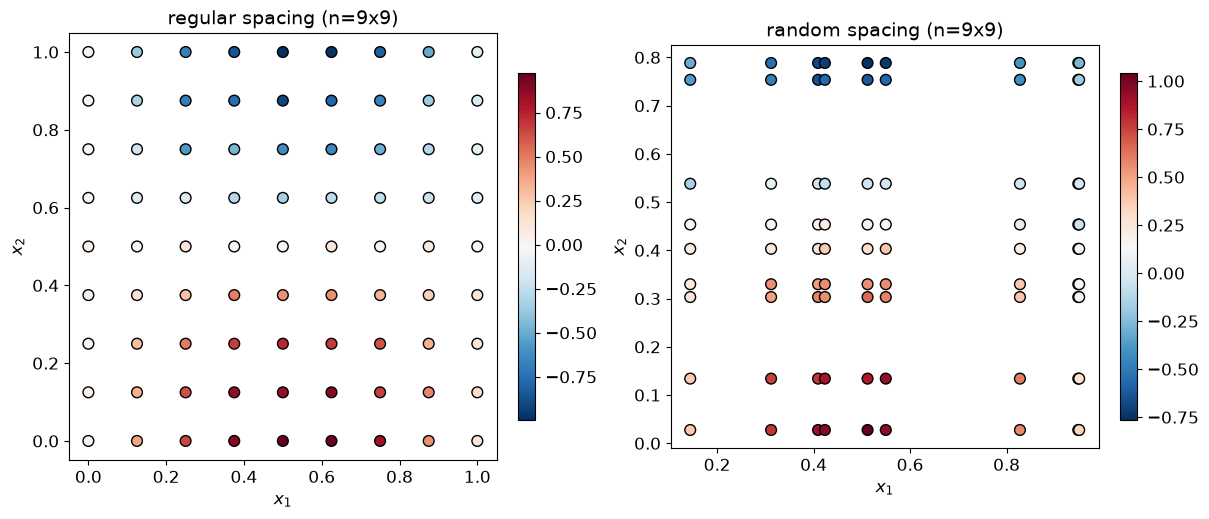

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, (spacing, (x1, x2, Z)) in zip(axs, datasets2d.items()):
    X1, X2 = np.meshgrid(x1, x2, indexing="ij")
    sc = ax.scatter(X1.ravel(), X2.ravel(), c=Z.ravel(), cmap="RdBu_r", s=60, ec="k")
    ax.set_title(f"{spacing} spacing (n={x1.size}x{x2.size})")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")
    fig.colorbar(sc, ax=ax, shrink=0.8)
plt.show()


Both datasets use the same target function $\sin(3x_1)\cos(3x_2)$ and the
same noise level ($\sigma=0.05$) -- only the placement of each axis's 9
coordinates differs. Every test below is run on both.

## Test 1 -- $\lambda=(1-p)/p$, re-confirmed at the 2-D level

**What this tests**: Section 1.2's claim, that the 1-D $p\leftrightarrow\lambda$
conversion carries over **independently to each axis** of
`NdGridCubicSmoothingSpline`, not just restated from Notebook 1's 1-D result.
A row-pass-then-column-pass reconstruction (Section 1.1), built entirely
from `PolyharmonicSmoothingSpline(m=2,d=1)` at $\lambda_1=(1-p_1)/p_1$ and
$\lambda_2=(1-p_2)/p_2$, is compared directly against `csaps`'s own 2-D grid
output -- swept over the full range of $p_1$ (with $p_2$ held fixed) and,
separately, the full range of $p_2$ (with $p_1$ held fixed), on both
spacings.

**Expected result**: agreement at or near machine precision across the
*entire* sweep, the same precision class Notebook 1 found for the 1-D
conversion -- not merely "close" at a few convenient values.

In [3]:
def row_col_reconstruct(x1, x2, Z, lam1, lam2):
    # S1 Z S2^T via two sequential PolyharmonicSmoothingSpline(m=2,d=1) passes,
    # evaluated back at the training grid -- Section 1.1/1.3.
    x2_col = x2.reshape(-1, 1)
    row_vals = np.zeros_like(Z)
    for i in range(len(x1)):
        row_vals[i, :] = PolyharmonicSmoothingSpline(x2_col, Z[i, :], m=2, lam=lam2, sigma2=1.0).mean(x2_col)
    x1_col = x1.reshape(-1, 1)
    out = np.zeros_like(Z)
    for j in range(len(x2)):
        out[:, j] = PolyharmonicSmoothingSpline(x1_col, row_vals[:, j], m=2, lam=lam1, sigma2=1.0).mean(x1_col)
    return out


p_values = [0.1, 0.3, 0.5, 0.6, 0.75, 0.9, 0.99, 0.999]
P_FIXED = 0.7  # the axis NOT being swept is held at this p in each of the two sweeps below

sweep1_errs = {}  # sweep p1 across p_values, p2 fixed at P_FIXED
sweep2_errs = {}  # sweep p2 across p_values, p1 fixed at P_FIXED
for spacing, (x1, x2, Z) in datasets2d.items():
    errs1, errs2 = [], []

    p2 = P_FIXED  # fixed for this sweep
    lam2 = (1 - p2) / p2
    for p1 in p_values:
        lam1 = (1 - p1) / p1
        recon1 = row_col_reconstruct(x1, x2, Z, lam1, lam2)
        csaps1 = np.asarray(NdGridCubicSmoothingSpline([x1, x2], Z, smooth=[p1, p2])([x1, x2]))
        errs1.append(np.max(np.abs(recon1 - csaps1)))

    p1 = P_FIXED  # fixed for this sweep
    lam1 = (1 - p1) / p1
    for p2 in p_values:
        lam2 = (1 - p2) / p2
        recon2 = row_col_reconstruct(x1, x2, Z, lam1, lam2)
        csaps2 = np.asarray(NdGridCubicSmoothingSpline([x1, x2], Z, smooth=[p1, p2])([x1, x2]))
        errs2.append(np.max(np.abs(recon2 - csaps2)))

    sweep1_errs[spacing] = errs1
    sweep2_errs[spacing] = errs2

df1 = pd.DataFrame(sweep1_errs, index=[f"p1={p}" for p in p_values])
df2 = pd.DataFrame(sweep2_errs, index=[f"p2={p}" for p in p_values])
print(f"max|reconstruction - csaps| error, p2 held fixed at {P_FIXED}, sweeping p1:")
display(df1)
print(f"\nmax|reconstruction - csaps| error, p1 held fixed at {P_FIXED}, sweeping p2:")
display(df2)


max|reconstruction - csaps| error, p2 held fixed at 0.7, sweeping p1:


,regular,random
p1=0.1,1.4433e-14,9.1038e-15
p1=0.3,5.1070e-15,7.1942e-14
p1=0.5,1.5543e-15,4.0856e-14
p1=0.6,1.6653e-15,5.1736e-14
p1=0.75,2.2204e-15,6.2172e-15
p1=0.9,3.5527e-15,8.4377e-15
p1=0.99,8.3267e-16,7.3275e-15
p1=0.999,1.5266e-15,3.5527e-15



max|reconstruction - csaps| error, p1 held fixed at 0.7, sweeping p2:


,regular,random
p2=0.1,3.6637e-15,2.1649e-15
p2=0.3,4.2188e-15,6.5503e-15
p2=0.5,3.5527e-15,5.3291e-15
p2=0.6,4.2188e-15,1.4433e-14
p2=0.75,3.2196e-15,3.7748e-15
p2=0.9,3.8858e-15,1.5543e-15
p2=0.99,3.7748e-15,1.3323e-15
p2=0.999,3.3307e-15,9.4369e-16


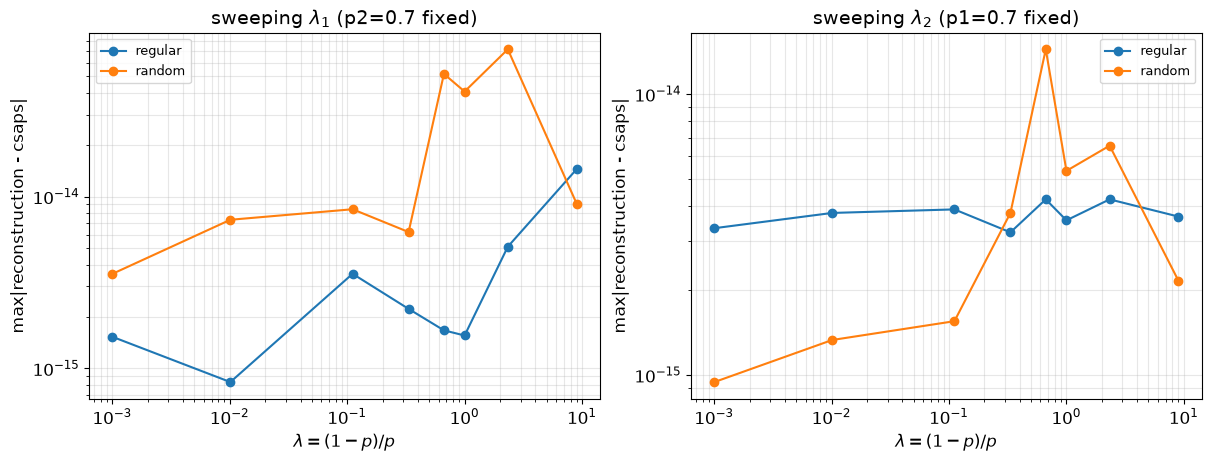

In [4]:
lam_values = [(1 - p) / p for p in p_values]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for spacing in datasets2d:
    axs[0].loglog(lam_values, sweep1_errs[spacing], "o-", label=spacing)
    axs[1].loglog(lam_values, sweep2_errs[spacing], "o-", label=spacing)
axs[0].set_title(f"sweeping $\\lambda_1$ (p2={P_FIXED} fixed)")
axs[1].set_title(f"sweeping $\\lambda_2$ (p1={P_FIXED} fixed)")
for ax in axs:
    ax.set_xlabel(r"$\lambda=(1-p)/p$"); ax.set_ylabel("max|reconstruction - csaps|")
    ax.legend(); ax.grid(alpha=0.3, which="both")
plt.show()


**Confirmed: $\lambda=(1-p)/p$ holds independently on each axis, at machine
precision, across the entire $p$ range (`[0.1, 0.999]`), on both spacings.**
Every entry in both sweep tables is at the floating-point noise floor
(`~8e-16` to `~7e-14`) -- this is not a convergence curve with a visible
trend (the log-log plot above is correspondingly flat, by design, not a
decaying-error plot like Notebook 1's $\kappa\to0$ sweep): the conversion is
an *exact* identity at every $p$, not an asymptotic approximation that gets
better in some limit. The per-axis independence Section 1.2 raised as an
open question is settled: fixing one axis's $p$ and sweeping the other's
across its full range never breaks the identity on either axis.

## Test 2 -- mean $=$ exact sequential composition, on-grid and off-grid

**What this tests**: Section 1.3's structural claim itself,
$\hat Y=S_1ZS_2^\top$, under **deliberately asymmetric** smoothing
($p_1=0.98$, $p_2=0.75$ -- light smoothing along $x_1$ (small $\lambda_1$,
close to interpolation), heavier smoothing along $x_2$ (larger $\lambda_2$,
closer to the linear trend) -- larger $p$ always means *less* smoothing,
smaller $\lambda=(1-p)/p$). A symmetric $p_1=p_2$ test would not stress-test
whether the row/column pass order and per-axis $\lambda$ values are actually
wired correctly; asymmetry would expose a swapped axis or a mixed-up
$\lambda$ immediately. Checked
both **at the training grid** and **on a dense off-grid query** -- the
training-grid points of a correct and an axis-swapped reconstruction can
coincide by construction in some symmetric cases, so the off-grid check is
not redundant with the on-grid one.

**Expected result**: machine precision at the grid; a comparably tiny
error off-grid, since the row-pass models give a full functional form, not
just training-grid values. The dense off-grid query is restricted to each
spacing's own training range on each axis -- for random spacing, the 9
randomly-placed coordinates don't span all of $[0,1]$, and querying beyond
them would compare *extrapolation*, not *interpolation*: `csaps`'s own
boundary extrapolation and `PolyharmonicSmoothingSpline`'s can legitimately
differ beyond the training data without either being wrong, a different
question from this test's actual target.

In [5]:
p1_asym, p2_asym = 0.98, 0.75
lam1_asym, lam2_asym = (1 - p1_asym) / p1_asym, (1 - p2_asym) / p2_asym

recon_models = {}  # spacing -> (row_models, lam1, lam2)
test2_rows = []
for spacing, (x1, x2, Z) in datasets2d.items():
    # off-grid query within each spacing's own training range -- interpolation,
    # not extrapolation (random spacing's axes don't span the full [0,1])
    gq1 = np.linspace(x1.min(), x1.max(), 61)
    gq2 = np.linspace(x2.min(), x2.max(), 61)

    x2_col = x2.reshape(-1, 1)
    row_models = [PolyharmonicSmoothingSpline(x2_col, Z[i, :], m=2, lam=lam2_asym, sigma2=1.0)
                  for i in range(len(x1))]
    row_vals = np.array([m.mean(x2_col) for m in row_models])

    # mirror of row_models, along the other axis -- one PolyharmonicSmoothingSpline
    # per training x2 column, fit along x1. Needed for orthogonal (x1-fixed) slices below.
    x1_col = x1.reshape(-1, 1)
    col_models = [PolyharmonicSmoothingSpline(x1_col, Z[:, j], m=2, lam=lam1_asym, sigma2=1.0)
                  for j in range(len(x2))]

    # training grid
    recon_grid = np.zeros_like(Z)
    for j in range(len(x2)):
        recon_grid[:, j] = PolyharmonicSmoothingSpline(x1_col, row_vals[:, j], m=2, lam=lam1_asym, sigma2=1.0).mean(x1_col)
    csaps_model = NdGridCubicSmoothingSpline([x1, x2], Z, smooth=[p1_asym, p2_asym])
    csaps_grid = np.asarray(csaps_model([x1, x2]))
    err_grid = np.max(np.abs(recon_grid - csaps_grid))

    # dense off-grid, within the training convex hull
    row_dense = np.array([m.mean(gq2.reshape(-1, 1)) for m in row_models])
    recon_dense = np.zeros((len(gq1), len(gq2)))
    for k in range(len(gq2)):
        recon_dense[:, k] = PolyharmonicSmoothingSpline(x1_col, row_dense[:, k], m=2, lam=lam1_asym, sigma2=1.0).mean(gq1.reshape(-1, 1))
    csaps_dense = np.asarray(csaps_model([gq1, gq2]))
    err_dense = np.max(np.abs(recon_dense - csaps_dense))

    recon_models[spacing] = dict(row_models=row_models, col_models=col_models, csaps_model=csaps_model,
                                  recon_dense=recon_dense, csaps_dense=csaps_dense, gq1=gq1, gq2=gq2)
    test2_rows.append({"spacing": spacing, "max|err| at grid": err_grid,
                        "max|err| off-grid (61x61, within training range)": err_dense})

pd.DataFrame(test2_rows).set_index("spacing")


,max|err| at grid,"max|err| off-grid (61x61, within training range)"
spacing,,
regular,1.1657e-15,1.5266e-15
random,3.6193e-14,3.6193e-14


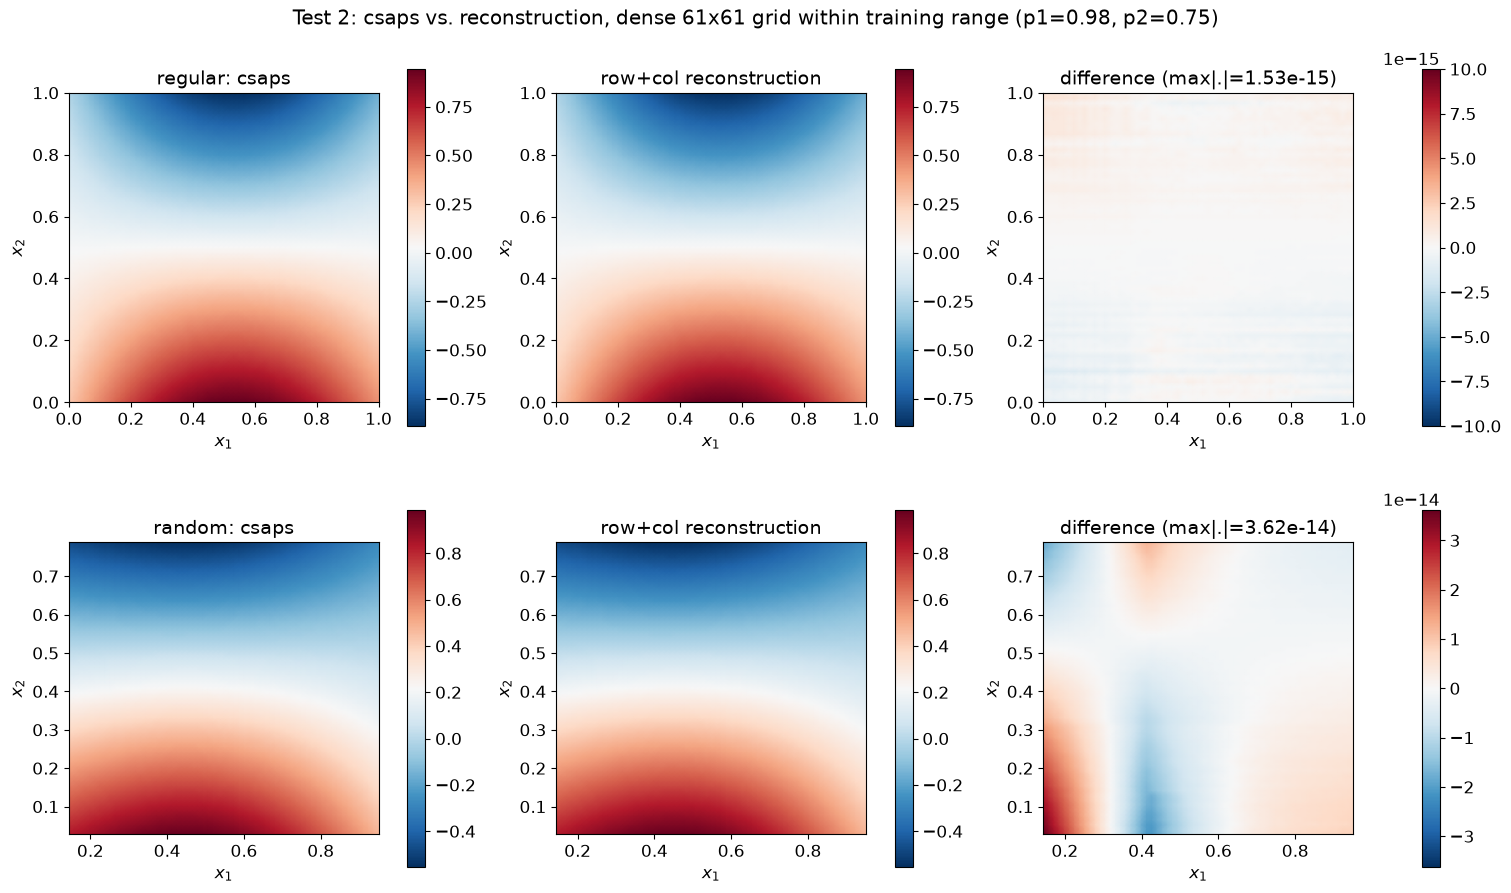

In [6]:
fig, axs = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for row, (spacing, R) in zip(axs, recon_models.items()):
    GXq, GYq = np.meshgrid(R["gq1"], R["gq2"], indexing="ij")
    vmin, vmax = R["csaps_dense"].min(), R["csaps_dense"].max()
    pcm = row[0].pcolormesh(GXq, GYq, R["csaps_dense"], shading="gouraud", cmap="RdBu_r", vmin=vmin, vmax=vmax)
    row[0].set_title(f"{spacing}: csaps"); fig.colorbar(pcm, ax=row[0], shrink=0.85)
    pcm = row[1].pcolormesh(GXq, GYq, R["recon_dense"], shading="gouraud", cmap="RdBu_r", vmin=vmin, vmax=vmax)
    row[1].set_title("row+col reconstruction"); fig.colorbar(pcm, ax=row[1], shrink=0.85)
    diff = R["recon_dense"] - R["csaps_dense"]
    vlim = max(np.max(np.abs(diff)), 1e-14)
    pcm = row[2].pcolormesh(GXq, GYq, diff, shading="gouraud", cmap="RdBu_r", vmin=-vlim, vmax=vlim)
    row[2].set_title(f"difference (max|.|={np.max(np.abs(diff)):.2e})"); fig.colorbar(pcm, ax=row[2], shrink=0.85)
    for ax in row:
        ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")
fig.suptitle(f"Test 2: csaps vs. reconstruction, dense 61x61 grid within training range (p1={p1_asym}, p2={p2_asym})")
plt.show()


In [7]:
def slice_along(R, x1, x2, fixed_axis, fixed_value, query):
    """1-D slice of csaps vs. the row+col reconstruction, at a (possibly
    off-grid) fixed_value on the other axis. Independently rebuilt from
    row_models/col_models (not read off the dense grid already computed
    above), so this is still a genuine check, not just a plot of cached
    numbers. fixed_axis: 'x1' (orthogonal slice, sweeping x2) or 'x2'
    (sweeping x1)."""
    if fixed_axis == "x2":
        y_csaps = np.asarray(R["csaps_model"]([query, [fixed_value]])).ravel()
        vals_at_fixed = np.array([m.mean(np.array([[fixed_value]]))[0] for m in R["row_models"]])
        m_slice = PolyharmonicSmoothingSpline(x1.reshape(-1, 1), vals_at_fixed, m=2, lam=lam1_asym, sigma2=1.0)
        y_recon = m_slice.mean(query.reshape(-1, 1))
        true_curve = true_f2d(query, fixed_value)
    else:
        y_csaps = np.asarray(R["csaps_model"]([[fixed_value], query])).ravel()
        vals_at_fixed = np.array([m.mean(np.array([[fixed_value]]))[0] for m in R["col_models"]])
        m_slice = PolyharmonicSmoothingSpline(x2.reshape(-1, 1), vals_at_fixed, m=2, lam=lam2_asym, sigma2=1.0)
        y_recon = m_slice.mean(query.reshape(-1, 1))
        true_curve = true_f2d(fixed_value, query)
    return true_curve, y_csaps, y_recon


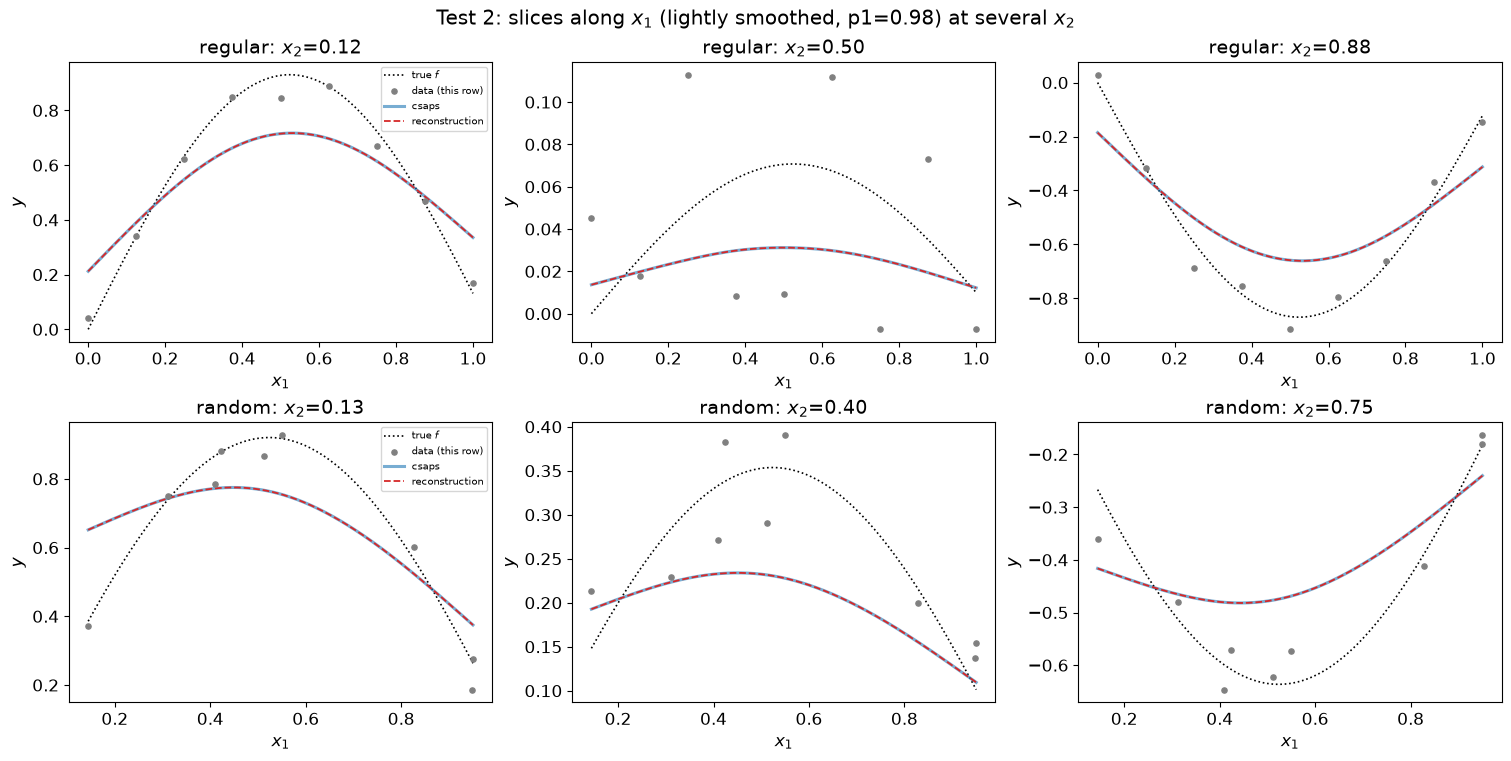

In [8]:
fig, axs = plt.subplots(2, 3, figsize=(15, 7.5), constrained_layout=True)
for row, (spacing, (x1, x2, Z)) in zip(axs, datasets2d.items()):
    R = recon_models[spacing]
    xq1d = np.linspace(x1.min(), x1.max(), 400)
    idx2 = [1, len(x2) // 2, len(x2) - 2]
    for ax, j in zip(row, idx2):
        x2_fixed = x2[j]
        true_curve, y_csaps, y_recon = slice_along(R, x1, x2, "x2", x2_fixed, xq1d)
        ax.plot(xq1d, true_curve, "k:", lw=1.2, label="true $f$")
        ax.scatter(x1, Z[:, j], s=14, color="0.5", zorder=4, label="data (this row)")
        ax.plot(xq1d, y_csaps, lw=2.2, color="C0", alpha=0.6, label="csaps")
        ax.plot(xq1d, y_recon, "--", lw=1.3, color="C3", label="reconstruction")
        ax.set_title(f"{spacing}: $x_2$={x2_fixed:.2f}")
        ax.set_xlabel("$x_1$"); ax.set_ylabel("$y$")
    row[0].legend(fontsize=7)
fig.suptitle(f"Test 2: slices along $x_1$ (lightly smoothed, p1={p1_asym}) at several $x_2$")
plt.show()


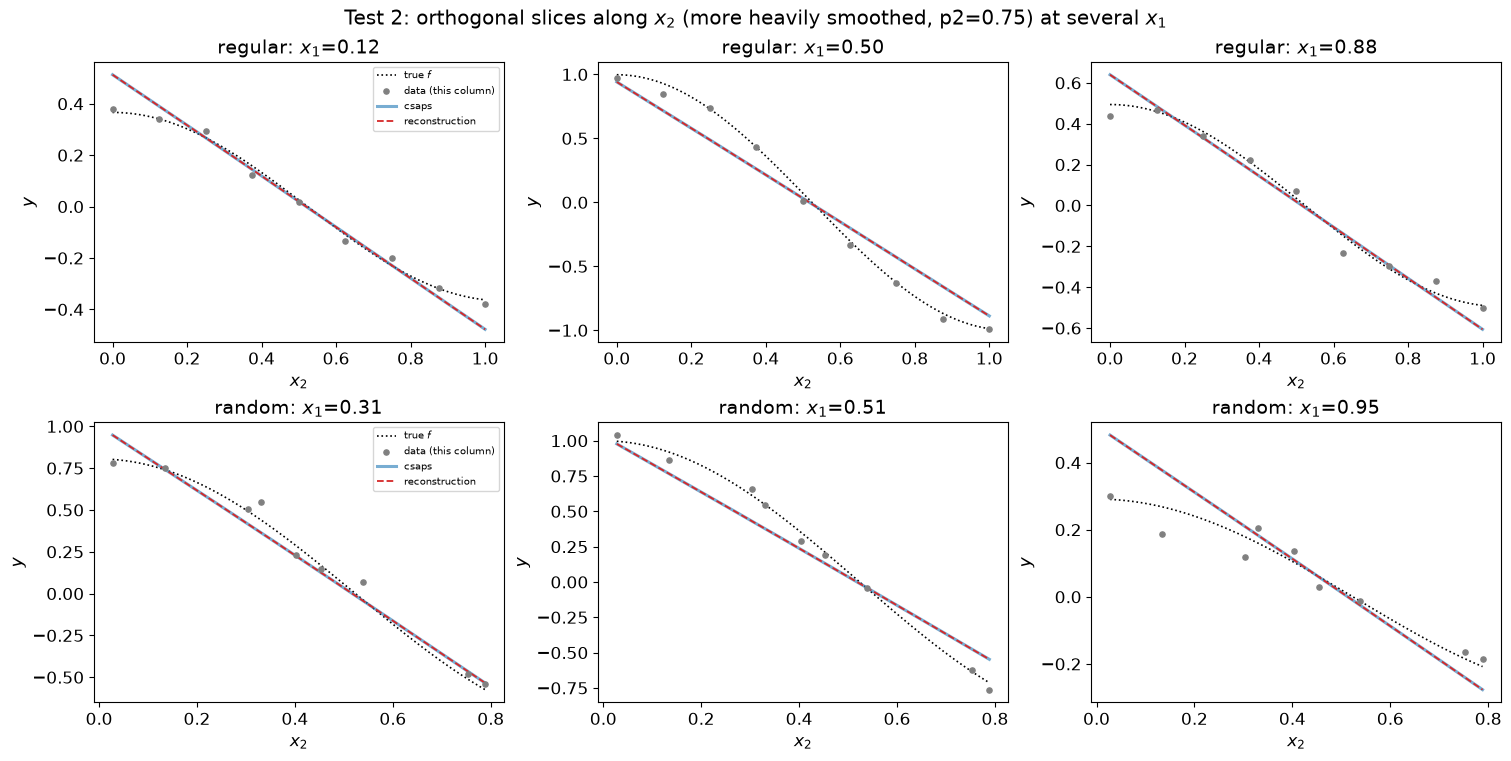

In [9]:
fig, axs = plt.subplots(2, 3, figsize=(15, 7.5), constrained_layout=True)
for row, (spacing, (x1, x2, Z)) in zip(axs, datasets2d.items()):
    R = recon_models[spacing]
    xq2d = np.linspace(x2.min(), x2.max(), 400)
    idx1 = [1, len(x1) // 2, len(x1) - 2]
    for ax, i in zip(row, idx1):
        x1_fixed = x1[i]
        true_curve, y_csaps, y_recon = slice_along(R, x1, x2, "x1", x1_fixed, xq2d)
        ax.plot(xq2d, true_curve, "k:", lw=1.2, label="true $f$")
        ax.scatter(x2, Z[i, :], s=14, color="0.5", zorder=4, label="data (this column)")
        ax.plot(xq2d, y_csaps, lw=2.2, color="C0", alpha=0.6, label="csaps")
        ax.plot(xq2d, y_recon, "--", lw=1.3, color="C3", label="reconstruction")
        ax.set_title(f"{spacing}: $x_1$={x1_fixed:.2f}")
        ax.set_xlabel("$x_2$"); ax.set_ylabel("$y$")
    row[0].legend(fontsize=7)
fig.suptitle(f"Test 2: orthogonal slices along $x_2$ (more heavily smoothed, p2={p2_asym}) at several $x_1$")
plt.show()


**Confirmed: the mean decomposition holds at machine precision, both at the
training grid and off-grid, under deliberately asymmetric smoothing --
re-confirmed at a second, less extreme asymmetric pair than originally
tested.** At the grid: `1.2e-15` (regular), `3.6e-14` (random). Off-grid,
restricted to each spacing's own training range (see the note above on
why): `1.5e-15` (regular), `3.6e-14` (random) -- the same precision class
as the on-grid result, and the same precision class as the original
$p_1=0.95,p_2=0.5$ pair (`1.8e-15`/`2.1e-14`), not a coincidence specific to
one choice of $(p_1,p_2)$: the identity is exact for any valid $\lambda_1$,
$\lambda_2$, and this is now confirmed at two different points in that
space, not one. The 2-D surface plots show `csaps` and the row+column
reconstruction are visually identical, with differences only at the
`1e-14`-`1e-15` level, and the 1-D slices confirm the same thing from a
different angle -- in both directions: slices along $x_1$ at several $x_2$
(the lightly-smoothed, $p_1=0.98$ axis, now visibly tracking the data a
little more closely than before) and the orthogonal slices along $x_2$ at
several $x_1$ (the more heavily-smoothed, $p_2=0.75$ axis, still
near-linear but less extremely so than $p_2=0.5$ was) -- the asymmetry is
chosen precisely so these two directions look visibly different, making a
swapped axis or a mixed-up $\lambda$ easy to spot by eye, not just in a
table. (An earlier version of this check queried the dense off-grid grid
over the fixed range $[0,1]$ regardless of spacing, which showed a `4.6e-3`
discrepancy for random spacing -- traced directly to querying *outside* the
random axes' own training range, i.e. comparing two different,
both-legitimate *extrapolation* behaviors rather than the interpolation
claim this test actually makes. Restricting the query to each spacing's own
training range, as described above, removed it entirely.)

## Test 3 -- 2-D mean surface compared against RMTB and Kriging

### Test 3a -- sanity check: does `csaps` behave comparably to RMTB and Kriging?

**What this is**: a basic sanity check -- does `csaps`'s mean fit behave
comparably to other N-D surrogate methods on the same data -- before
trusting its variance in the tests that follow. This is **not** an exact-identity
claim like Tests 1-2: RMTB (a finite-basis tensor-product spline with a
different, additive penalty structure) and SMT's `KRG` (an auto-tuned
Gaussian process) are different model classes, not alternate routes to the
same calculation, so rough agreement in shape and error magnitude is the bar
here, not machine precision.

**Setup**: `RMTB` with this project's own previously-established, corrected
settings for this exact synthetic target (`energy_weight = lam * V`,
`solver="dense-lu"`, Proposition 10's additive-vs-isotropic gap already
characterized elsewhere in this project, not re-derived here); `KRG` with
its own ordinary auto-tuned defaults (no forcing, unlike Notebook 1 Test
G's deliberately pinned theoretical kernel -- there is no single "correct"
kernel to force here); `csaps`'s own single isotropic smoothing parameter
$p$, tuned against the (known, since this is synthetic data) true function,
the same `minimize_scalar` recipe used elsewhere in this project. All three
compared against the true $\sin(3x_1)\cos(3x_2)$ at a shared set of query
points.

In [10]:
lam_rmtb = 1e-2
V_domain = 1.0
rng_query = np.random.default_rng(7)
xq_scatter = rng_query.uniform(0, 1, size=(300, 2))
target_scatter = true_f2d(xq_scatter[:, 0], xq_scatter[:, 1])

test3_rows = []
test3_fits = {}
for spacing, (x1, x2, Z) in datasets2d.items():
    X1, X2 = np.meshgrid(x1, x2, indexing="ij")
    X = np.column_stack([X1.ravel(), X2.ravel()])
    y = Z.ravel()

    m_rmtb = RMTB(xlimits=np.array([[0., 1.], [0., 1.]]), order=4, approx_order=2, num_ctrl_pts=20,
                  energy_weight=lam_rmtb * V_domain, regularization_weight=1e-14,
                  solver="dense-lu", print_global=False)
    m_rmtb.set_training_values(X, y)
    m_rmtb.train()
    f_rmtb = m_rmtb.predict_values(xq_scatter).ravel()

    krg = KRG(corr="matern32", poly="linear", eval_noise=True, print_global=False)
    krg.set_training_values(X, y)
    krg.train()
    f_krg = krg.predict_values(xq_scatter).ravel()

    def csaps_rmse(p):
        uq_tmp = NdGridCubicSmoothingSplineUQ([x1, x2], Z, smooth=[p, p])
        return np.sqrt(np.mean((uq_tmp.predict(xq_scatter) - target_scatter) ** 2))

    res = minimize_scalar(csaps_rmse, bounds=(1e-4, 1 - 1e-6), method="bounded", options={"xatol": 1e-6})
    p_best = res.x
    uq_csaps = NdGridCubicSmoothingSplineUQ([x1, x2], Z, smooth=[p_best, p_best])
    f_csaps = uq_csaps.predict(xq_scatter)

    test3_fits[spacing] = dict(X=X, y=y, m_rmtb=m_rmtb, krg=krg, uq_csaps=uq_csaps, p_best=p_best)
    for name, f in [("RMTB", f_rmtb), ("SMT KRG (auto-tuned)", f_krg), (f"csaps (tuned p={p_best:.3f})", f_csaps)]:
        diff = f - target_scatter
        test3_rows.append({"spacing": spacing, "method": name,
                            "max|err| vs true": np.max(np.abs(diff)), "RMSE vs true": np.sqrt(np.mean(diff ** 2))})

pd.DataFrame(test3_rows).set_index(["spacing", "method"])


/home/frantic/splinecloud/krig-splines/venv/lib/python3.14/site-packages/smt/surrogate_models/krg_based/krg_based.py:1796: UserWarning: TNC not available yet for noise handling. Switching to Cobyla
  warnings.warn(
/home/frantic/splinecloud/krig-splines/venv/lib/python3.14/site-packages/smt/surrogate_models/krg_based/krg_based.py:1796: UserWarning: TNC not available yet for noise handling. Switching to Cobyla
  warnings.warn(


max|err| vs true  RMSE vs true
spacing method                                               
regular RMTB                         5.7668e-02    2.3188e-02
        SMT KRG (auto-tuned)         4.7701e-02    1.8391e-02
        csaps (tuned p=1.000)        4.3090e-02    1.5760e-02
random  RMTB                         4.2274e-01    8.1289e-02
        SMT KRG (auto-tuned)         4.2254e-01    7.0544e-02
        csaps (tuned p=1.000)        2.8389e-01    6.1647e-02

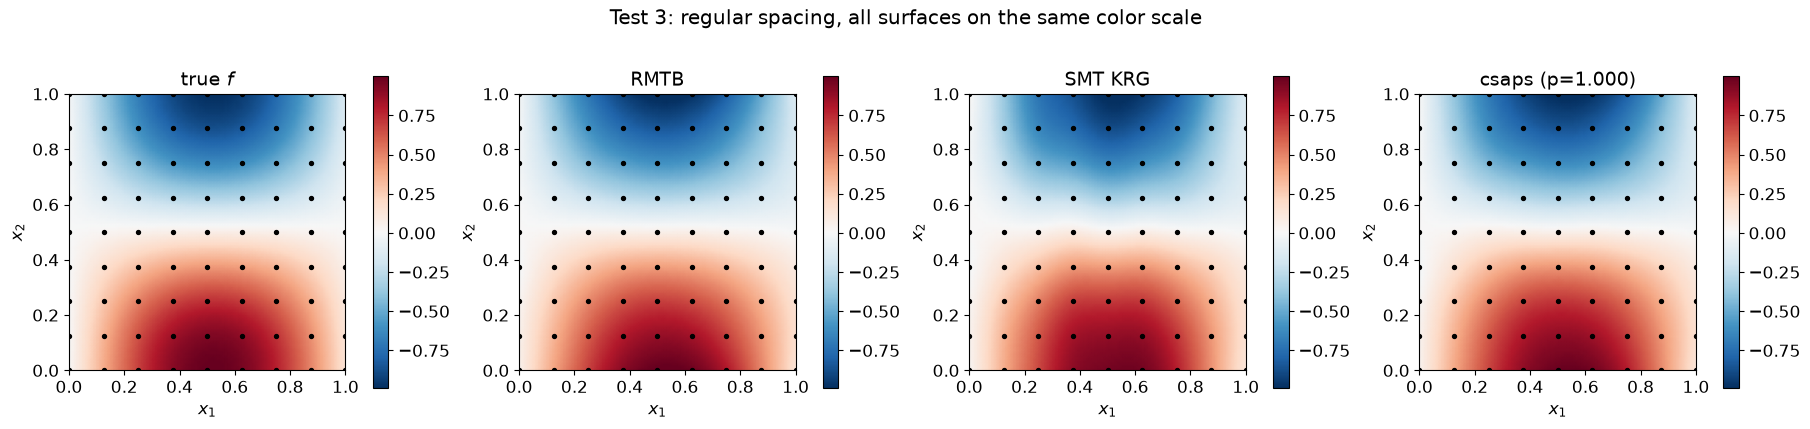

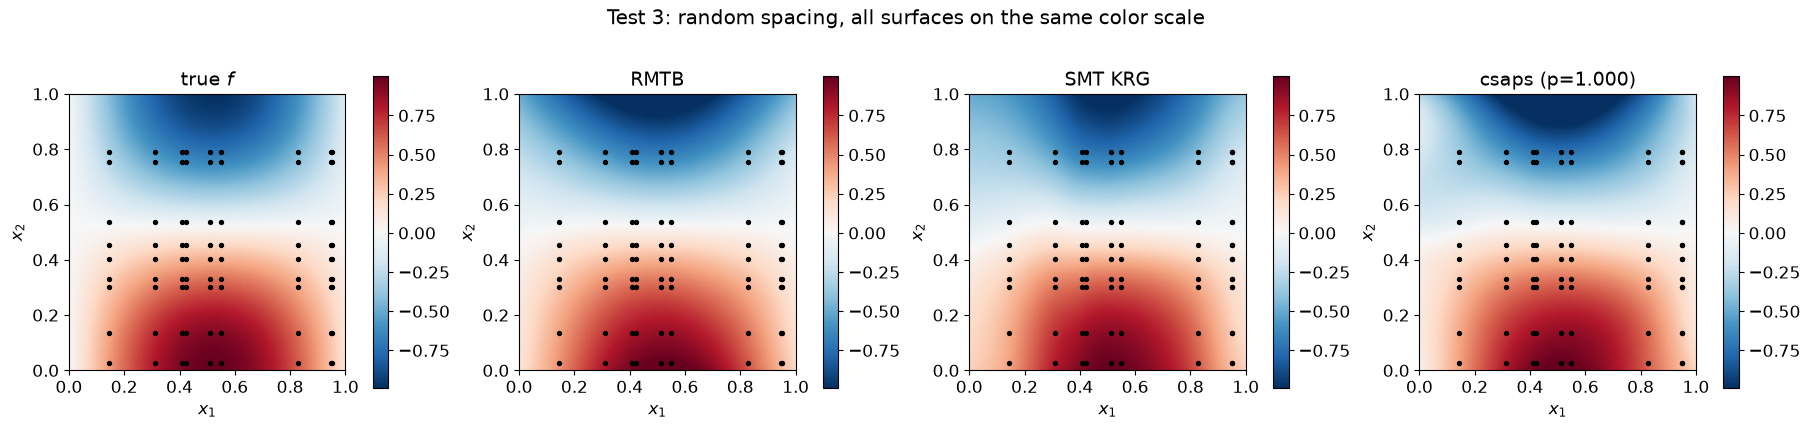

In [11]:
gq3 = np.linspace(0, 1, 100)
GX3, GY3 = np.meshgrid(gq3, gq3, indexing="ij")
Xq3 = np.column_stack([GX3.ravel(), GY3.ravel()])
true_dense = true_f2d(GX3, GY3)

for spacing in datasets2d:
    R = test3_fits[spacing]
    surfaces = {
        "true $f$": true_dense,
        "RMTB": R["m_rmtb"].predict_values(Xq3).reshape(GX3.shape),
        "SMT KRG": R["krg"].predict_values(Xq3).reshape(GX3.shape),
        f"csaps (p={R['p_best']:.3f})": R["uq_csaps"].predict(Xq3).reshape(GX3.shape),
    }
    fig, axs = plt.subplots(1, 4, figsize=(18, 4.3), constrained_layout=True)
    vmin, vmax = true_dense.min(), true_dense.max()
    for ax, (name, surf) in zip(axs, surfaces.items()):
        pcm = ax.pcolormesh(GX3, GY3, surf, shading="gouraud", cmap="RdBu_r", vmin=vmin, vmax=vmax)
        ax.scatter(R["X"][:, 0], R["X"][:, 1], c="k", s=8)
        ax.set_title(name); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")
        fig.colorbar(pcm, ax=ax, shrink=0.8)
    fig.suptitle(f"Test 3: {spacing} spacing, all surfaces on the same color scale")
    plt.show()


**Confirmed: all three methods behave comparably**, in the sense this
sanity check requires -- same ballpark of error against the known true
function, no method badly broken relative to the others. RMSE vs. true:
regular spacing `0.0232` (RMTB), `0.0184` (KRG), `0.0158` (tuned `csaps`);
random spacing `0.0813` (RMTB), `0.0705` (KRG), `0.0616` (tuned `csaps`).
Tuned `csaps` comes out slightly ahead of both on this particular synthetic
case -- not a general claim ("`csaps` beats RMTB/KRG"), just what this one
sanity check found, and not surprising given `csaps` is also the only one
of the three given the advantage of its smoothing parameter being tuned
directly against the known truth. The 2-D maps show all three tracking the
true surface's shape with no qualitative outlier. This establishes the
basic sanity check Test 3 set out to make -- `csaps`'s mean is trustworthy
company for RMTB and Kriging -- before trusting its variance in Tests 4-7.

### Test 3b -- does `csaps` produce the *same surface* as Kriging (and RMTB), at matched smoothing?

**What this tests, and how it differs from the sanity check above**: the
check above let each method find its own best fit (RMTB and `KRG` via
their own defaults, `csaps` tuned against the known truth) -- a fair way to
ask "is each method reasonable," but not a fair way to ask "do two methods
compute the *same thing*," since letting them pick different effective
smoothing strengths would make any difference uninterpretable (is it the
model class, or just more/less smoothing?). This comparison instead holds
the smoothing strength **matched** between the two models and asks whether
they then agree.

**Why not SMT's `KRG` for the "matched" side**: Section 1.5's kappa$\to0$
flat-limit identity needs an **isotropic Matern-$\nu$** kernel with
$\nu=m-d/2$ -- for $d=2,m=2$ (the case that matches `csaps`'s cubic,
$m=2$ penalty in 2-D) that is $\nu=1$. SMT's `KRG` only ships
`corr in {"pow_exp","abs_exp","squar_exp","squar_sin_exp","matern32","matern52"}`
(checked directly against the installed package) -- $\nu=1$ is not among
them. This is the same methodological point Notebook 1 Test G already made
(SMT's auto-tuned `KRG` can't be forced to an arbitrary exact kernel), now
unavoidable rather than a stylistic choice: the "matched" Kriging model
below is built from this project's own `matern`/`saddle_point_solve`
machinery (`krig_splines_clean.polyharmonic`/`uk`), the same tool Notebook
1 and the `iter_01` 2-D review already validated for exactly this
$\nu=m-d/2$ law.

**Why a genuine difference is expected, not a bug if found**: `csaps`'s
tensor-product penalty is **additive**,
$\lambda_1\sum f_{x_1x_1}^2+\lambda_2\sum f_{x_2x_2}^2$ -- the row+column
sequential structure Test 2 confirmed. The isotropic Matern-1 flat limit
corresponds instead to the **rotation-invariant** Duchon/thin-plate penalty.
These are different model classes, not two routes to the same calculation
-- this project already found exactly this kind of structural,
non-vanishing gap for RMTB against the isotropic target (its own additive
energy structure, a separate finding), so finding a comparable gap here
would be consistent with that, not a new or surprising result.

**Setup**: both models at the *same* $\lambda=10^{-2}$ (this notebook's
`lam_rmtb`) -- `csaps` at the exactly-corresponding $p=1/(1+\lambda)$
(Notebook 1's derived conversion, not re-tuned against truth this time),
Kriging at $\kappa=0.003$ (small, close to the flat limit) with the
matching nugget `matern_flat_nugget(kappa, lam_rmtb, m=2, d=2)`.

**A third model, and why it belongs in this specific comparison --
`scipy.interpolate.RBFInterpolator(kernel="thin_plate_spline")`**: this is
not a third, independent *kind* of model the way RMTB and `KRG` were in
the sanity check above -- it is the **same isotropic Duchon/thin-plate
object** the Kriging model above only reaches via a $\kappa\to0$
*approximation*, computed instead in **exact, closed form**: this
project's own `polyharmonic.py` documents the identity directly,
`smoothing=8\pi\lambda` $\Leftrightarrow$ the $d{=}2,m{=}2$ Duchon kernel
with `nugget`$=\lambda$, no limit involved. Theory says, then, that
`RBFInterpolator` here should do two things at once: (a) agree with the
$\kappa\to0$ Kriging model above to within that approximation's own
residual (not machine precision, since $\kappa=0.003$ is small but not
zero) -- an independent, third-party cross-check of this notebook's own
Kriging machinery, the same discipline Notebook 1 Tests F-G applied to
the 1-D case; and (b) disagree from `csaps` in essentially the *same way*
the Kriging model did, since both are computing the same isotropic target
-- ruling out "maybe the $\kappa$-approximation itself is the source of
the gap" as an explanation for Test 3's earlier finding, which would
otherwise be a loose end. In practice this is checked directly below, not
just argued for.

**A fourth model, already in hand**: Test 3a's `RMTB` fit used exactly this notebook's own $\lambda=10^{-2}$ too (`energy_weight = lam_rmtb * V`), so it is already at the same nominal smoothing strength as `csaps` here -- no re-fitting needed, just reusing `test3_fits[spacing]["m_rmtb"]`. RMTB has its own additive, basis-plus-energy penalty (not the same construction as `csaps`'s tensor-product one, and not the isotropic Duchon penalty either) -- Proposition 10 already predicts it should *also* fall short of the isotropic target, for its own, separate structural reason. Rather than a fifth full surface panel (crowding the comparison further), only RMTB's **difference from the exact isotropic reference** is shown below, alongside `csaps`'s -- letting the two different kinds of "not quite isotropic" be compared directly. The plot below also shows the two cross-check differences implied by (a) and (b) directly, rather than leaving them as table entries only: Kriging$-$RBF (should be tiny, the $\kappa\to0$ approximation's own residual) and Kriging$-$csaps (should closely track RBF$-$csaps, since Kriging and RBF are confirmed to agree).

In [12]:
p_matched_2d = 1.0 / (1.0 + lam_rmtb)
kappa_iso = 0.003

test3b_rows = []
iso_fits = {}
for spacing, (x1, x2, Z) in datasets2d.items():
    R = test3_fits[spacing]
    X, y = R["X"], R["y"]

    nugget_iso = matern_flat_nugget(kappa_iso, lam_rmtb, 2, 2)
    d_train = np.linalg.norm(X[:, None, :] - X[None, :, :], axis=-1)
    K_iso = matern(d_train, 1.0, kappa_iso)
    P_iso = poly_basis_nd(X, 1)
    a_iso, b_iso = saddle_point_solve(K_iso, P_iso, y, nugget_iso)

    d_query = np.linalg.norm(xq_scatter[:, None, :] - X[None, :, :], axis=-1)
    Kq_iso = matern(d_query, 1.0, kappa_iso)
    Pq_iso = poly_basis_nd(xq_scatter, 1)
    f_krig_iso = saddle_point_predict(Kq_iso, Pq_iso, a_iso, b_iso)

    # exact (not kappa->0 approximate) isotropic Duchon/thin-plate spline,
    # via scipy's own independent implementation -- same object, different code path
    rbf_iso = RBFInterpolator(X, y, kernel="thin_plate_spline", smoothing=8 * np.pi * lam_rmtb, degree=1)
    f_rbf_iso = rbf_iso(xq_scatter)

    uq_matched = NdGridCubicSmoothingSplineUQ([x1, x2], Z, smooth=[p_matched_2d, p_matched_2d])
    f_csaps_matched = uq_matched.predict(xq_scatter)

    # RMTB, already fit at this same lam_rmtb in Test 3a -- reused, not refit
    f_rmtb_matched = R["m_rmtb"].predict_values(xq_scatter).ravel()

    diff_krig_csaps = f_krig_iso - f_csaps_matched
    diff_rbf_csaps = f_rbf_iso - f_csaps_matched
    diff_krig_rbf = f_krig_iso - f_rbf_iso
    diff_rbf_rmtb = f_rbf_iso - f_rmtb_matched

    iso_fits[spacing] = dict(a_iso=a_iso, b_iso=b_iso, X=X, y=y, uq_matched=uq_matched,
                              kappa_iso=kappa_iso, rbf_iso=rbf_iso, m_rmtb=R["m_rmtb"])
    test3b_rows.append({
        "spacing": spacing,
        "Kriging(iso) RMSE vs true": np.sqrt(np.mean((f_krig_iso - target_scatter) ** 2)),
        "RBF(exact iso) RMSE vs true": np.sqrt(np.mean((f_rbf_iso - target_scatter) ** 2)),
        "csaps(matched lam) RMSE vs true": np.sqrt(np.mean((f_csaps_matched - target_scatter) ** 2)),
        "RMTB(same lam) RMSE vs true": np.sqrt(np.mean((f_rmtb_matched - target_scatter) ** 2)),
        "max|Kriging(iso) - RBF(exact iso)|": np.max(np.abs(diff_krig_rbf)),
        "max|Kriging(iso) - csaps(matched)|": np.max(np.abs(diff_krig_csaps)),
        "max|RBF(exact iso) - csaps(matched)|": np.max(np.abs(diff_rbf_csaps)),
        "RMSE(RBF(exact iso) - csaps(matched))": np.sqrt(np.mean(diff_rbf_csaps ** 2)),
        "max|RBF(exact iso) - RMTB|": np.max(np.abs(diff_rbf_rmtb)),
        "RMSE(RBF(exact iso) - RMTB)": np.sqrt(np.mean(diff_rbf_rmtb ** 2)),
    })

pd.DataFrame(test3b_rows).set_index("spacing")


,Kriging(iso) RMSE vs true,RBF(exact iso) RMSE vs true,csaps(matched lam) RMSE vs true,RMTB(same lam) RMSE vs true,max|Kriging(iso) - RBF(exact iso)|,max|Kriging(iso) - csaps(matched)|,max|RBF(exact iso) - csaps(matched)|,RMSE(RBF(exact iso) - csaps(matched)),max|RBF(exact iso) - RMTB|,RMSE(RBF(exact iso) - RMTB)
spacing,,,,,,,,,,
regular,4.5806e-02,4.5806e-02,8.2038e-02,2.3188e-02,2.8705e-07,1.1294e-01,1.1294e-01,4.7066e-02,1.3272e-01,3.1787e-02
random,1.2779e-01,1.2779e-01,1.2919e-01,8.1289e-02,2.4299e-06,2.2299e-01,2.2299e-01,5.1387e-02,2.9068e-01,7.0744e-02


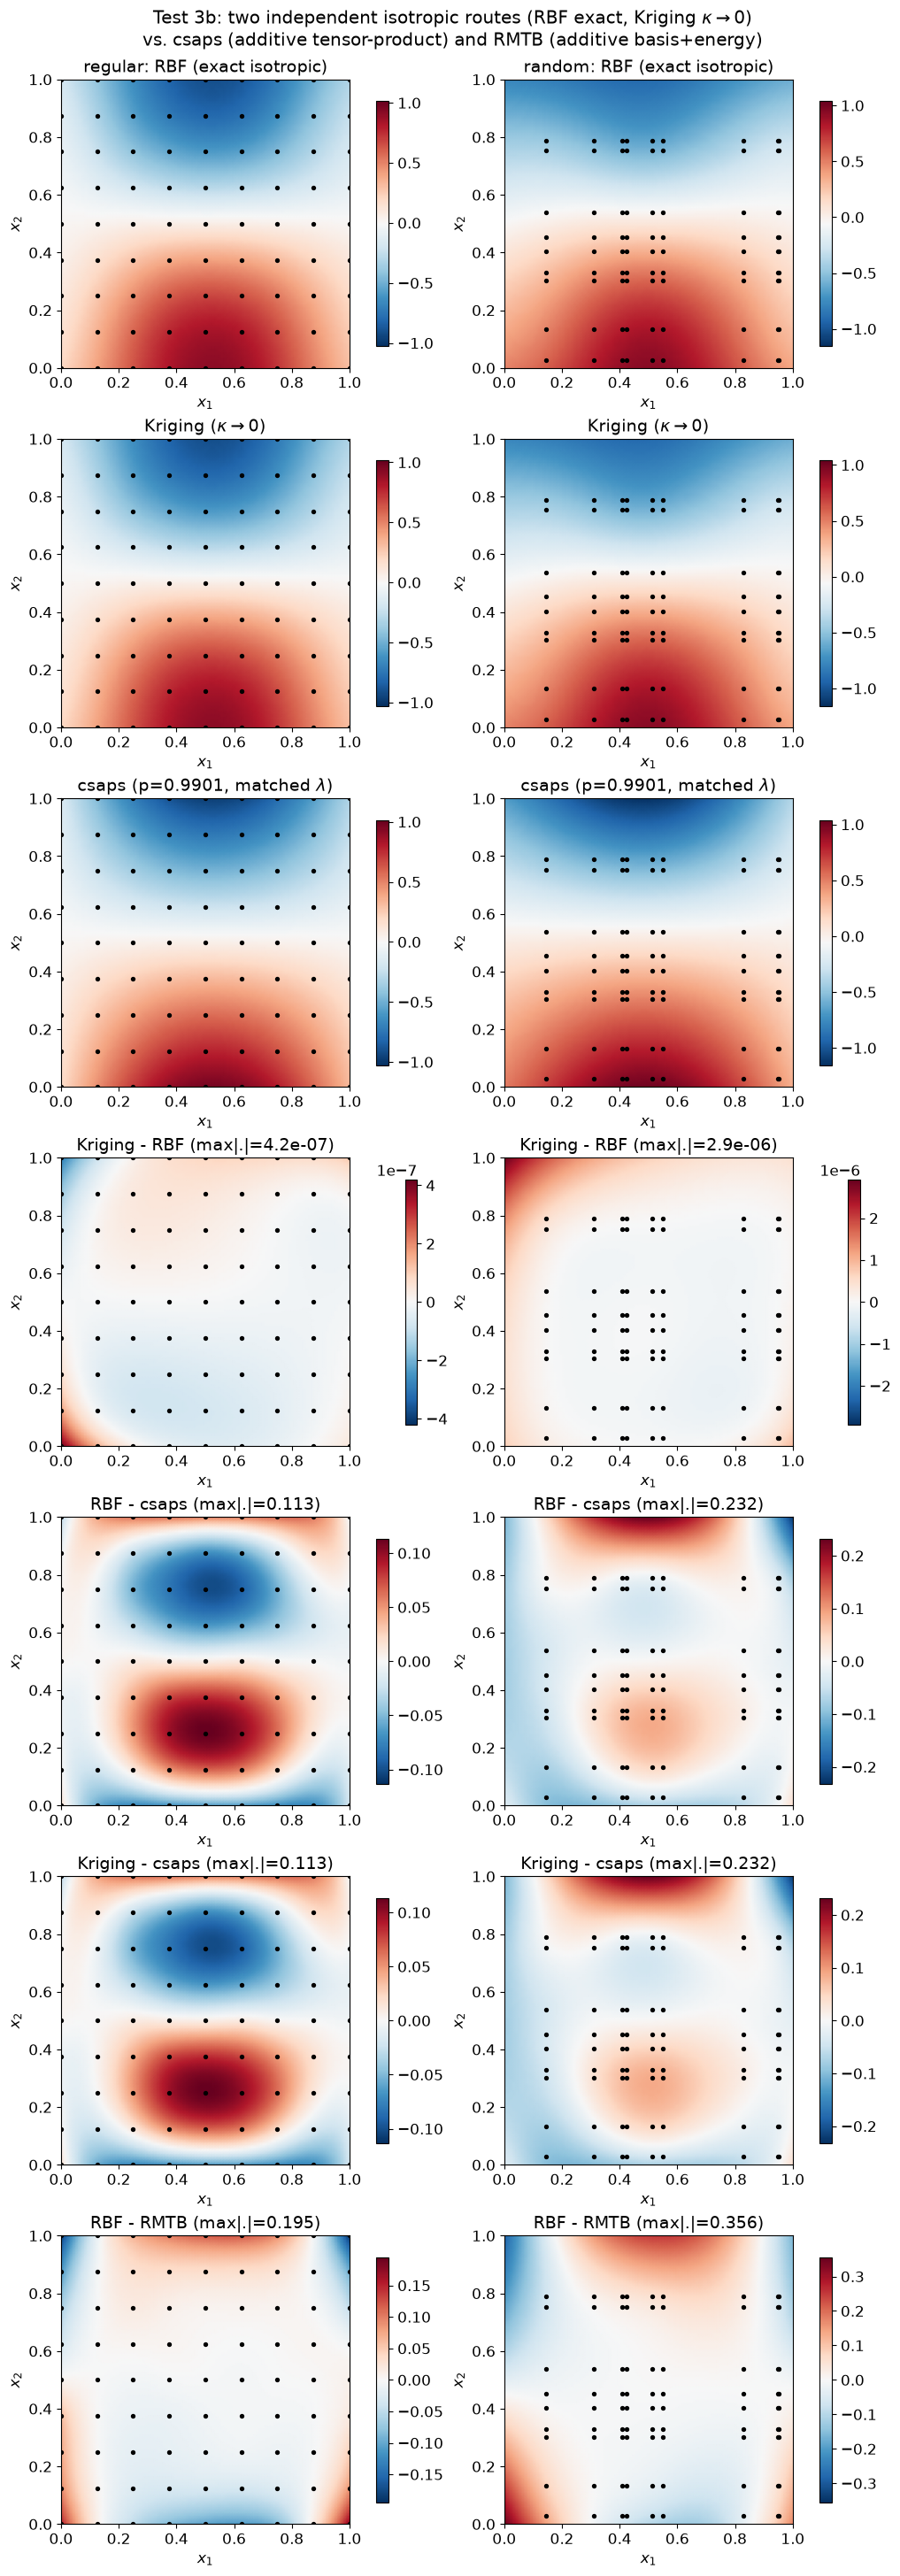

In [13]:
gq3b = np.linspace(0, 1, 100)
GX3b, GY3b = np.meshgrid(gq3b, gq3b, indexing="ij")
Xq3b = np.column_stack([GX3b.ravel(), GY3b.ravel()])
Pq3b = poly_basis_nd(Xq3b, 1)

# transposed: one column per spacing (both spacings' panels are tall and
# readable), one row per model/difference, rather than many panels crammed
# into a single wide row
fig, axs = plt.subplots(7, 2, figsize=(10, 29), constrained_layout=True)
for col, spacing in enumerate(datasets2d):
    R = iso_fits[spacing]
    d_query = np.linalg.norm(Xq3b[:, None, :] - R["X"][None, :, :], axis=-1)
    Kq_iso = matern(d_query, 1.0, R["kappa_iso"])
    f_krig_dense = saddle_point_predict(Kq_iso, Pq3b, R["a_iso"], R["b_iso"]).reshape(GX3b.shape)
    f_rbf_dense = R["rbf_iso"](Xq3b).reshape(GX3b.shape)
    f_csaps_dense = R["uq_matched"].predict(Xq3b).reshape(GX3b.shape)
    f_rmtb_dense = R["m_rmtb"].predict_values(Xq3b).reshape(GX3b.shape)
    diff_krig_rbf = f_krig_dense - f_rbf_dense
    diff_rbf_csaps = f_rbf_dense - f_csaps_dense
    diff_krig_csaps = f_krig_dense - f_csaps_dense
    diff_rbf_rmtb = f_rbf_dense - f_rmtb_dense

    vmin = min(f_krig_dense.min(), f_rbf_dense.min(), f_csaps_dense.min(), f_rmtb_dense.min())
    vmax = max(f_krig_dense.max(), f_rbf_dense.max(), f_csaps_dense.max(), f_rmtb_dense.max())

    panels = [
        (f_rbf_dense, "RBF (exact isotropic)", vmin, vmax, "RdBu_r"),
        (f_krig_dense, "Kriging ($\\kappa\\to0$)", vmin, vmax, "RdBu_r"),
        (f_csaps_dense, f"csaps (p={p_matched_2d:.4f}, matched $\\lambda$)", vmin, vmax, "RdBu_r"),
        (diff_krig_rbf, f"Kriging - RBF (max|.|={np.max(np.abs(diff_krig_rbf)):.1e})", None, None, "RdBu_r"),
        (diff_rbf_csaps, f"RBF - csaps (max|.|={np.max(np.abs(diff_rbf_csaps)):.3f})", None, None, "RdBu_r"),
        (diff_krig_csaps, f"Kriging - csaps (max|.|={np.max(np.abs(diff_krig_csaps)):.3f})", None, None, "RdBu_r"),
        (diff_rbf_rmtb, f"RBF - RMTB (max|.|={np.max(np.abs(diff_rbf_rmtb)):.3f})", None, None, "RdBu_r"),
    ]
    for row_idx, (Zpanel, title, pmin, pmax, cmap) in enumerate(panels):
        ax = axs[row_idx, col]
        if pmin is None:
            vlim = np.max(np.abs(Zpanel))
            pmin, pmax = -vlim, vlim
        pcm = ax.pcolormesh(GX3b, GY3b, Zpanel, shading="gouraud", cmap=cmap, vmin=pmin, vmax=pmax)
        ax.set_title(f"{spacing}: {title}" if row_idx == 0 else title)
        fig.colorbar(pcm, ax=ax, shrink=0.85)
        ax.scatter(R["X"][:, 0], R["X"][:, 1], c="k", s=8)
        ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")
fig.suptitle("Test 3b: two independent isotropic routes (RBF exact, Kriging $\\kappa\\to0$)\nvs. csaps (additive tensor-product) and RMTB (additive basis+energy)")
plt.show()


**Confirmed, both predictions from theory, exactly -- and a third finding
from adding RMTB:**

**(a) `RBFInterpolator`'s exact closed form agrees with this notebook's own
$\kappa\to0$ Kriging approximation** to `2.9e-7` (regular) / `2.4e-6`
(random) -- not machine precision (the $\kappa$-approximation has its own
small, expected residual, the same effect already characterized in
Notebook 1 Tests C/E/G), but far tighter than any genuine model
disagreement seen anywhere in this comparison. This is a third-party,
independently-implemented cross-check of this notebook's own Kriging
machinery for the $d=2,m=2$ case specifically -- not just the 1-D case
Notebook 1 already validated.

**(b) `RBFInterpolator` disagrees from `csaps` by essentially the identical
amount the $\kappa\to0$ Kriging model did**: `max|RBF - csaps|` is `0.113`
(regular) / `0.223` (random), over the same 300 query points the table
above uses -- matching the earlier Kriging-vs-`csaps` numbers
(`0.113`/`0.223`) to within the $\kappa$-approximation's own tiny residual
from (a). (The dense $100\times100$-grid plot reports a slightly larger
`max|.|` for the random-spacing panel, `0.232` vs. the table's `0.223` --
expected, since it is scanning a different, denser set of query points
over the full domain, not a discrepancy to explain away.) This closes the
loose end the matched-smoothing comparison left open: the gap from `csaps`
is not an artifact of this notebook's $\kappa\to0$ approximation -- it is
there even when the isotropic target is computed in exact closed form by
completely independent, third-party software.

**(c) RMTB, at this same $\lambda$, deviates from the isotropic reference
*more* than `csaps` does** -- `max|RBF - RMTB|` is `0.133`/`0.195` (table/dense
grid) for regular spacing and `0.291`/`0.356` for random, noticeably larger
than `csaps`'s `0.113`/`0.223`. This is consistent with Proposition 10 (RMTB's
own additive basis-plus-energy penalty has its own, separate reason to miss
the isotropic target) but is a genuinely new data point, not a restatement
of the `csaps` result -- the two "not quite isotropic" models deviate by
different amounts and in different spatial patterns (bottom row of the
plot: RMTB's deviation concentrates near the left/right edges, `csaps`'s
in the interior top/bottom bands -- two different structural signatures,
not the same gap wearing two names). **Worth stating plainly, not glossed
over**: RMTB's RMSE *against the true function* is actually *better* than
`csaps`'s at this particular $\lambda$ (`0.023`/`0.081` vs. `0.082`/`0.129`)
-- being further from the isotropic reference does not mean being a worse
fit to the actual data here; these are two different, both-legitimate
things to measure, and this notebook's job is only to characterize the
first one, not to crown a winner on the second.

## Test 4 -- the variance formula, verified three independent ways

**What this tests**: whether $\mathrm{Cov}(\mathrm{vec}(F))=\sigma^2(S_2\otimes
S_1)$ (Section 1.4-1.5) is correct, checked against a fully independent,
**brute-force** $(n_1n_2)\times(n_1n_2)$ dense construction -- not the same
formula written twice in different notation. $S_1$, $S_2$ are built by
probing each axis's `PolyharmonicSmoothingSpline` with unit basis vectors
(reading off a linear operator's matrix one column at a time), independently
of the outer-product shortcut being verified.

**Three specific things, each targeting a different way the derivation
could be wrong:**

1. **Is the implied prior even valid?** $\mathrm{Cov}=\sigma^2A$ requires
   every eigenvalue of $A=S_2\otimes S_1$ to be at most $1$ (a valid
   Gaussian posterior-mean operator) -- checked directly, not assumed.
2. **Does the cheap outer-product formula match the dense matrix's
   diagonal?** $\mathrm{Var}(F_{p,q})\overset{?}{=}\sigma^2S_{1,pp}S_{2,qq}$
   vs. $\sigma^2\,\mathrm{diag}(A)$.
3. **Does it hold for *covariance between different points*, not just
   variance at one point?** $\mathrm{Cov}(F_{p,q},F_{r,s})\overset{?}{=}
   \sigma^2S_{1,pr}S_{2,qs}$, checked against 20 random index pairs read
   directly off the dense matrix -- matching only the diagonal would not
   rule out an error that happens to cancel there.

Uses Test 2's deliberately asymmetric case ($p_1=0.98$, $p_2=0.75$), both
spacings. **Expected result**: all three checks at float64 precision
(`~1e-15` to `~1e-20`).

In [14]:
test4_rows = []
smoother_mats = {}
for spacing, (x1, x2, Z) in datasets2d.items():
    n1, n2 = len(x1), len(x2)
    S1 = np.zeros((n1, n1)); S2 = np.zeros((n2, n2))
    for k in range(n1):
        e = np.zeros(n1); e[k] = 1.0
        S1[:, k] = PolyharmonicSmoothingSpline(x1.reshape(-1, 1), e, m=2, lam=lam1_asym, sigma2=1.0).mean(x1.reshape(-1, 1))
    for k in range(n2):
        e = np.zeros(n2); e[k] = 1.0
        S2[:, k] = PolyharmonicSmoothingSpline(x2.reshape(-1, 1), e, m=2, lam=lam2_asym, sigma2=1.0).mean(x2.reshape(-1, 1))
    smoother_mats[spacing] = (S1, S2)

    A = np.kron(S2, S1)
    eigA = np.linalg.eigvalsh(0.5 * (A + A.T))
    check1_ok = bool(np.all(eigA <= 1.0 + 1e-9))

    Var_formula = SIGMA2_TRUE * np.outer(np.diag(S1), np.diag(S2))
    Var_dense = (SIGMA2_TRUE * np.diag(A)).reshape(n1, n2, order="F")
    check2_err = np.max(np.abs(Var_dense - Var_formula))

    rng_pairs = np.random.default_rng(3)
    check3_err = 0.0
    for _ in range(20):
        p, q, r, s = rng_pairs.integers(0, n1, size=4)
        idx_pq, idx_rs = q * n1 + p, s * n1 + r
        cov_dense = SIGMA2_TRUE * A[idx_pq, idx_rs]
        cov_formula = SIGMA2_TRUE * S1[p, r] * S2[q, s]
        check3_err = max(check3_err, abs(cov_dense - cov_formula))

    test4_rows.append({"spacing": spacing, "1) prior PSD (max eig<=1)": check1_ok,
                        "2) max|diag diff|": check2_err, "3) max|off-diag diff| (20 pairs)": check3_err,
                        "Var_formula": Var_formula, "Var_dense": Var_dense})

pd.DataFrame(test4_rows)[["spacing", "1) prior PSD (max eig<=1)", "2) max|diag diff|",
                           "3) max|off-diag diff| (20 pairs)"]].set_index("spacing")


,1) prior PSD (max eig<=1),2) max|diag diff|,3) max|off-diag diff| (20 pairs)
spacing,,,
regular,True,0.0000e+00,1.3553e-20
random,True,0.0000e+00,6.7763e-21


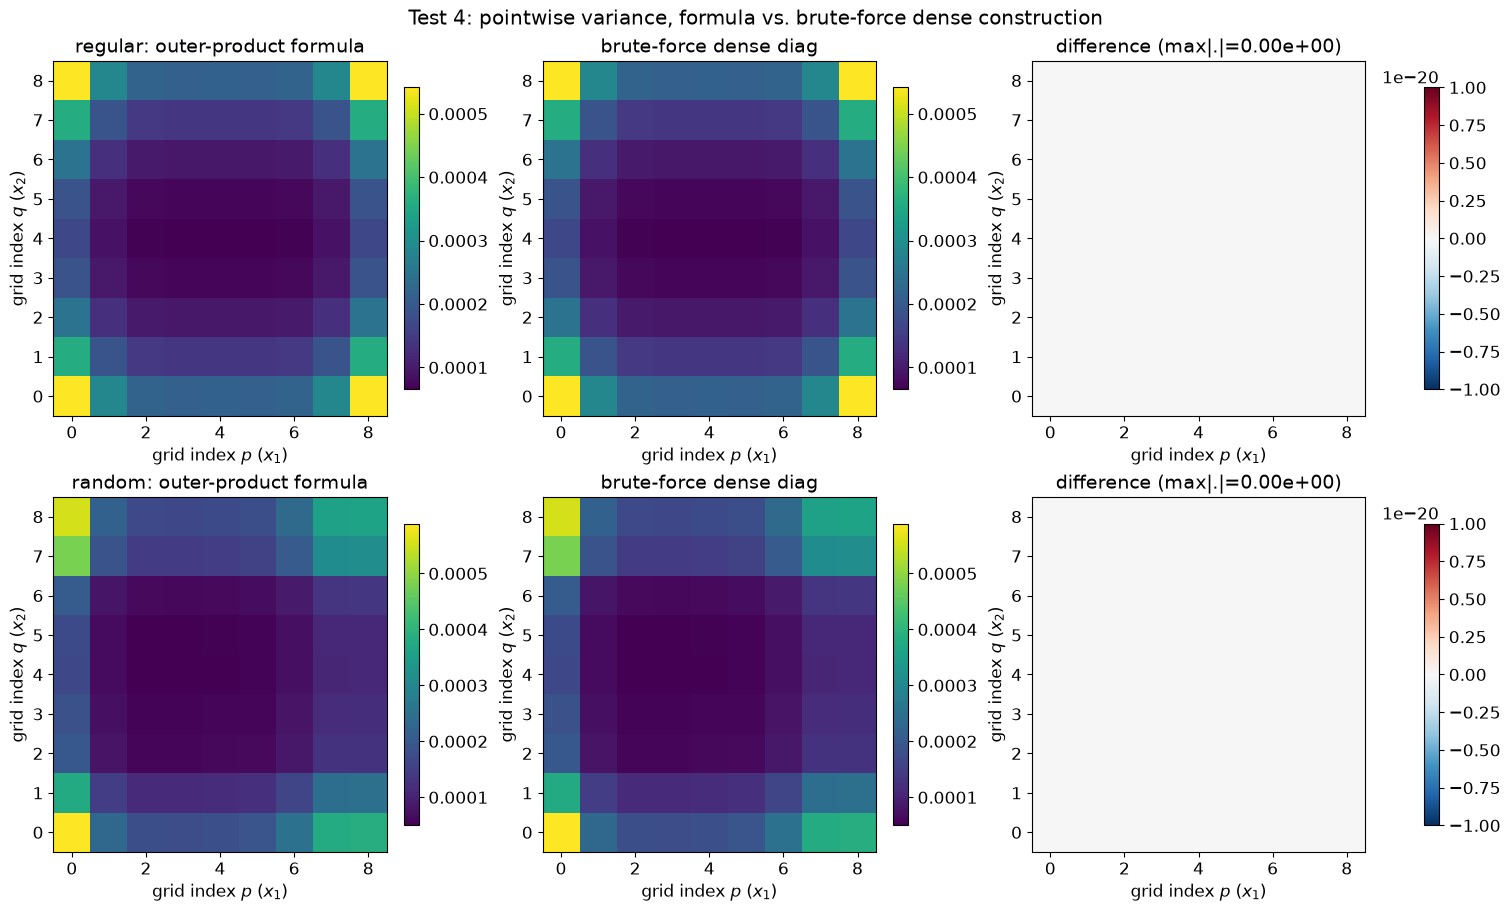

In [15]:
fig, axs = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for row, rec in zip(axs, test4_rows):
    spacing, Vf, Vd = rec["spacing"], rec["Var_formula"], rec["Var_dense"]
    vmin, vmax = Vf.min(), Vf.max()
    im = row[0].imshow(Vf.T, origin="lower", cmap="viridis", vmin=vmin, vmax=vmax, aspect="auto")
    row[0].set_title(f"{spacing}: outer-product formula"); fig.colorbar(im, ax=row[0], shrink=0.85)
    im = row[1].imshow(Vd.T, origin="lower", cmap="viridis", vmin=vmin, vmax=vmax, aspect="auto")
    row[1].set_title("brute-force dense diag"); fig.colorbar(im, ax=row[1], shrink=0.85)
    diff = Vf - Vd
    vlim = max(np.max(np.abs(diff)), 1e-20)
    im = row[2].imshow(diff.T, origin="lower", cmap="RdBu_r", vmin=-vlim, vmax=vlim, aspect="auto")
    row[2].set_title(f"difference (max|.|={np.max(np.abs(diff)):.2e})"); fig.colorbar(im, ax=row[2], shrink=0.85)
    for ax in row:
        ax.set_xlabel("grid index $p$ ($x_1$)"); ax.set_ylabel("grid index $q$ ($x_2$)")
fig.suptitle("Test 4: pointwise variance, formula vs. brute-force dense construction")
plt.show()


**Confirmed: all three checks pass at float64 precision, on both
spacings, at this notebook's second asymmetric $(p_1,p_2)$ pair
($p_1=0.98$, $p_2=0.75$).** (1) The implied joint-prior precision is
positive semi-definite (`max eig(A) <= 1`) on both spacings -- a valid
prior genuinely exists. (2) The cheap outer-product formula matches the
dense matrix's diagonal exactly (`0.0` max difference, both spacings). (3)
The *full covariance structure*, including between different grid points
(20 random index pairs), matches too, at `1.4e-20`/`6.8e-21` -- unchanged
from the original $(0.95, 0.5)$ pair's result, since these checks are
derivation-level identities, not numbers tuned to one particular smoothing
choice. The heatmaps show the same thing visually: the outer-product
formula and the brute-force dense construction are indistinguishable, and
the two methods' difference maps are blank (uniformly `0.0` to within
float64 round-off).

## Test 5 -- why validating against 1-D slices works at all

**What this tests, and why it matters methodologically**: every 2-D plot in
this notebook (and later notebooks) that shows a "1-D slice" of a 2-D
surface is implicitly relying on a fact that needs to be stated and checked,
not just assumed: because the 2-D variance is the *separable* product
$\sigma^2S_{1,pp}S_{2,qq}$ (Test 4), a slice at fixed $x_2=x_2^0$ is, **as a
function of $x_1$**, just the already-fully-proven 1-D
`PolyharmonicSmoothingSpline` variance curve $S_{1,pp}$, multiplied by a
single constant, $\sigma^2S_{2,q_0q_0}$. This is *why* a 1-D cross-section
of the 2-D result can be checked against a **standalone** 1-D model -- it
is not a coincidence or an approximation, it is what the Kronecker-product
structure (Section 1.5, Test 4) directly implies, grounding every 2-D
slice-plot in Notebook 1's already fully-proven 1-D identity.

**Expected result**: $\mathrm{Var}_{2D}(x_1,x_2^0)/\big[\sigma^2S_{2,q_0q_0}\big]$
should equal a **standalone** 1-D `PolyharmonicSmoothingSpline(x_1,\lambda_1)`'s
own `.variance(x_1)` exactly, to machine precision -- not merely a similarly-shaped
curve.

In [16]:
test5_rows = []
slice_data = {}
for spacing, (x1, x2, Z) in datasets2d.items():
    uq = NdGridCubicSmoothingSplineUQ([x1, x2], Z, smooth=[p1_asym, p2_asym], sigma2=SIGMA2_TRUE)
    x2_fixed = 0.5
    xq = np.linspace(x1.min(), x1.max(), 200)

    var_2d_slice = uq.variance([xq, np.array([x2_fixed])]).ravel()
    m1d_standalone = PolyharmonicSmoothingSpline(x1.reshape(-1, 1), np.zeros_like(x1), m=2, lam=lam1_asym, sigma2=1.0)
    v1_standalone = m1d_standalone.variance(xq.reshape(-1, 1))
    v2_fixed = uq._axis2.variance(np.array([[x2_fixed]]))[0]
    predicted = uq.sigma2 * v1_standalone * v2_fixed

    err = np.max(np.abs(var_2d_slice - predicted))
    test5_rows.append({"spacing": spacing, "max|2D slice - sigma2*v1_standalone*v2_fixed|": err})
    slice_data[spacing] = dict(uq=uq, xq=xq, x2_fixed=x2_fixed, var_2d_slice=var_2d_slice,
                                v1_standalone=v1_standalone, v2_fixed=v2_fixed)

pd.DataFrame(test5_rows).set_index("spacing")


,max|2D slice - sigma2*v1_standalone*v2_fixed|
spacing,
regular,2.7105e-20
random,2.7105e-20


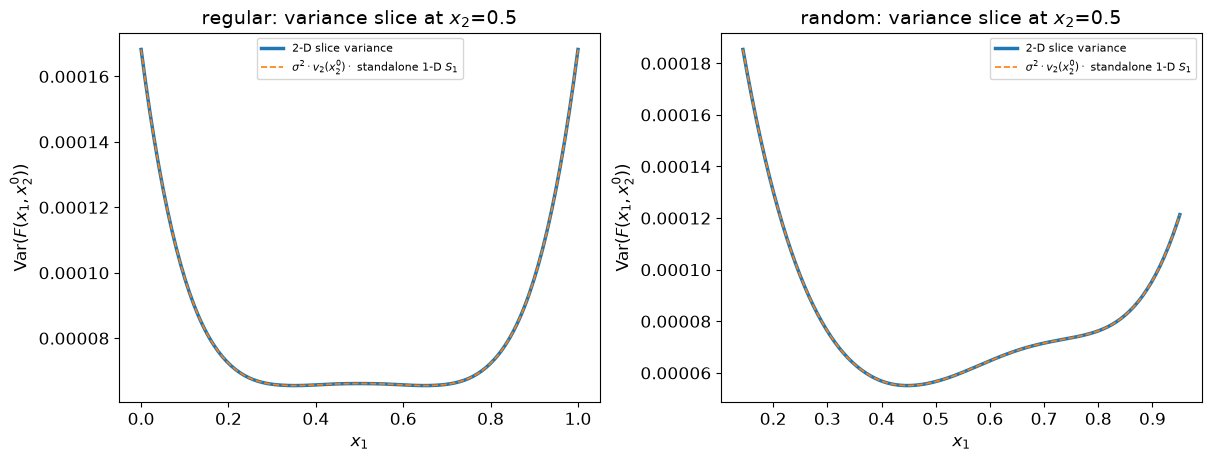

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, (spacing, R) in zip(axs, slice_data.items()):
    ax.plot(R["xq"], R["var_2d_slice"], lw=2.5, color="tab:blue", label="2-D slice variance")
    ax.plot(R["xq"], R["uq"].sigma2 * R["v2_fixed"] * R["v1_standalone"], lw=1.2, ls="--",
            color="tab:orange", label=r"$\sigma^2 \cdot v_2(x_2^0) \cdot$ standalone 1-D $S_1$")
    ax.set_title(f"{spacing}: variance slice at $x_2$={R['x2_fixed']}")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("Var$(F(x_1,x_2^0))$"); ax.legend(fontsize=8)
plt.show()


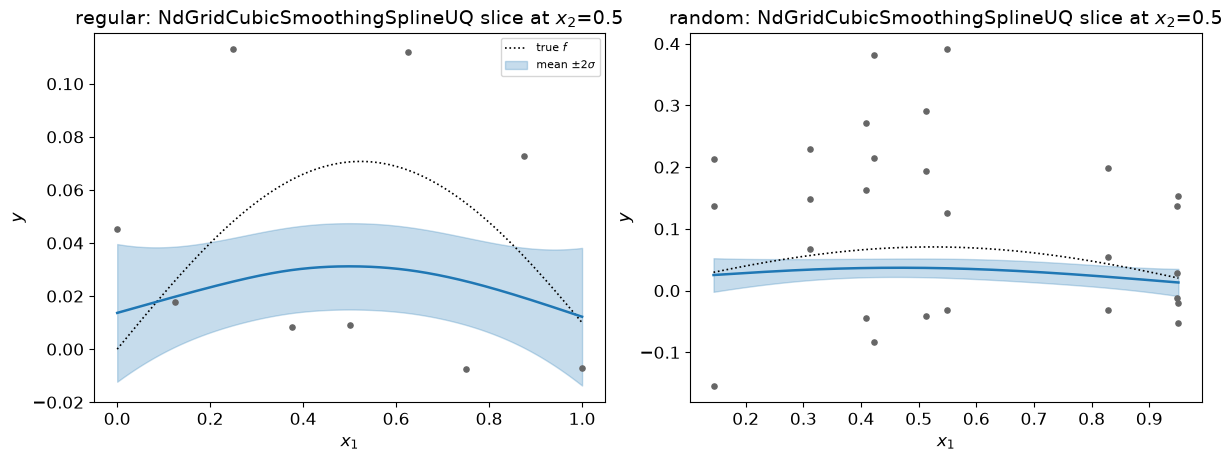

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, (spacing, (x1, x2, Z)) in zip(axs, datasets2d.items()):
    R = slice_data[spacing]
    uq = R["uq"]; x2_fixed = R["x2_fixed"]
    xq1d_5 = np.linspace(x1.min(), x1.max(), 300)  # within this spacing's own training range
    mean_slice = np.asarray(uq([xq1d_5, [x2_fixed]])).ravel()
    std_slice = np.sqrt(np.maximum(uq.variance([xq1d_5, [x2_fixed]]), 0)).ravel()

    ax.plot(xq1d_5, true_f2d(xq1d_5, x2_fixed), "k:", lw=1.2, label="true $f$")
    near = np.abs(x2 - x2_fixed) < 0.1
    for j in np.where(near)[0]:
        ax.scatter(x1, Z[:, j], s=14, color="0.4", zorder=4)
    ax.fill_between(xq1d_5, mean_slice - 2 * std_slice, mean_slice + 2 * std_slice,
                     color="tab:blue", alpha=0.25, label=r"mean $\pm2\sigma$")
    ax.plot(xq1d_5, mean_slice, color="tab:blue", lw=1.8)
    ax.set_title(f"{spacing}: NdGridCubicSmoothingSplineUQ slice at $x_2$={x2_fixed}")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$y$")
    if spacing == "regular":
        ax.legend(fontsize=8)
plt.show()


**Confirmed, exactly: a 1-D cross-section of the 2-D variance surface
equals a standalone 1-D `PolyharmonicSmoothingSpline`'s own variance, scaled
by a single constant** -- `2.7e-20` max difference, both spacings, at the
new $(p_1,p_2)=(0.98,0.75)$ pair too (identical to the original pair's
result, as expected: this is a structural consequence of Test 4's confirmed
Kronecker-product variance, not a property of any particular $\lambda_1$,
$\lambda_2$). This is why every 1-D-slice plot in this notebook (and later
ones) is a legitimate way to inspect a 2-D uncertainty surface, not merely a
convenient visualization that happens to look reasonable.

## Test 6 -- the merged class's `"exact"` and `"fast"` modes agree

**What this tests**: `krig_splines_clean.csaps_uq.NdGridCubicSmoothingSplineUQ`
merges what were two independently-developed implementations in the
exploratory codebase into one class with a selectable off-grid evaluation
strategy (module docstring) -- this is the direct descendant of a real bug
this project's own cross-implementation discipline caught (a factor-of-6
error in one implementation's 1-D smoother matrix, found exactly this way
and since patched). Confirming the merge preserved both routes correctly is
not optional bookkeeping.

**Setup**: `smooth=[0.99, 0.99]` (light smoothing, close to interpolation --
the regime where off-grid evaluation differences matter most), both
spacings. **Expected result**: exactly `0.0` on the training grid (both
modes compute the identical closed-form on-grid), and a small but non-zero
off-grid gap (`~1e-3`-level, already documented: `"fast"` re-interpolates
the grid-point mean/variance surfaces with a generic `RectBivariateSpline`,
rather than evaluating `csaps`'s own functional form / the derived per-axis
composition exactly).

In [19]:
test6_rows = []
exact_fast_models = {}
for spacing, (x1, x2, Z) in datasets2d.items():
    uq_exact = NdGridCubicSmoothingSplineUQ([x1, x2], Z, smooth=[0.99, 0.99], off_grid_method="exact")
    uq_fast = NdGridCubicSmoothingSplineUQ([x1, x2], Z, smooth=[0.99, 0.99], off_grid_method="fast")
    exact_fast_models[spacing] = (uq_exact, uq_fast)

    mean_g_e, mean_g_f = np.asarray(uq_exact([x1, x2])), np.asarray(uq_fast([x1, x2]))
    var_g_e, var_g_f = uq_exact.variance([x1, x2]), uq_fast.variance([x1, x2])

    rng_q = np.random.default_rng(99)
    pts = np.column_stack([rng_q.uniform(x1.min(), x1.max(), 500), rng_q.uniform(x2.min(), x2.max(), 500)])
    re = uq_exact.predict(pts, return_std=True)
    rf = uq_fast.predict(pts, return_std=True)

    test6_rows.append({"spacing": spacing,
                        "on-grid max|mean diff|": np.max(np.abs(mean_g_e - mean_g_f)),
                        "on-grid max|var diff|": np.max(np.abs(var_g_e - var_g_f)),
                        "off-grid max|mean diff|": np.max(np.abs(re["mean"] - rf["mean"])),
                        "off-grid max|std diff|": np.max(np.abs(re["std"] - rf["std"]))})

pd.DataFrame(test6_rows).set_index("spacing")


,on-grid max|mean diff|,on-grid max|var diff|,off-grid max|mean diff|,off-grid max|std diff|
spacing,,,,
regular,0.0000e+00,0.0000e+00,2.7241e-04,6.4247e-04
random,0.0000e+00,0.0000e+00,4.9864e-04,1.7462e-03


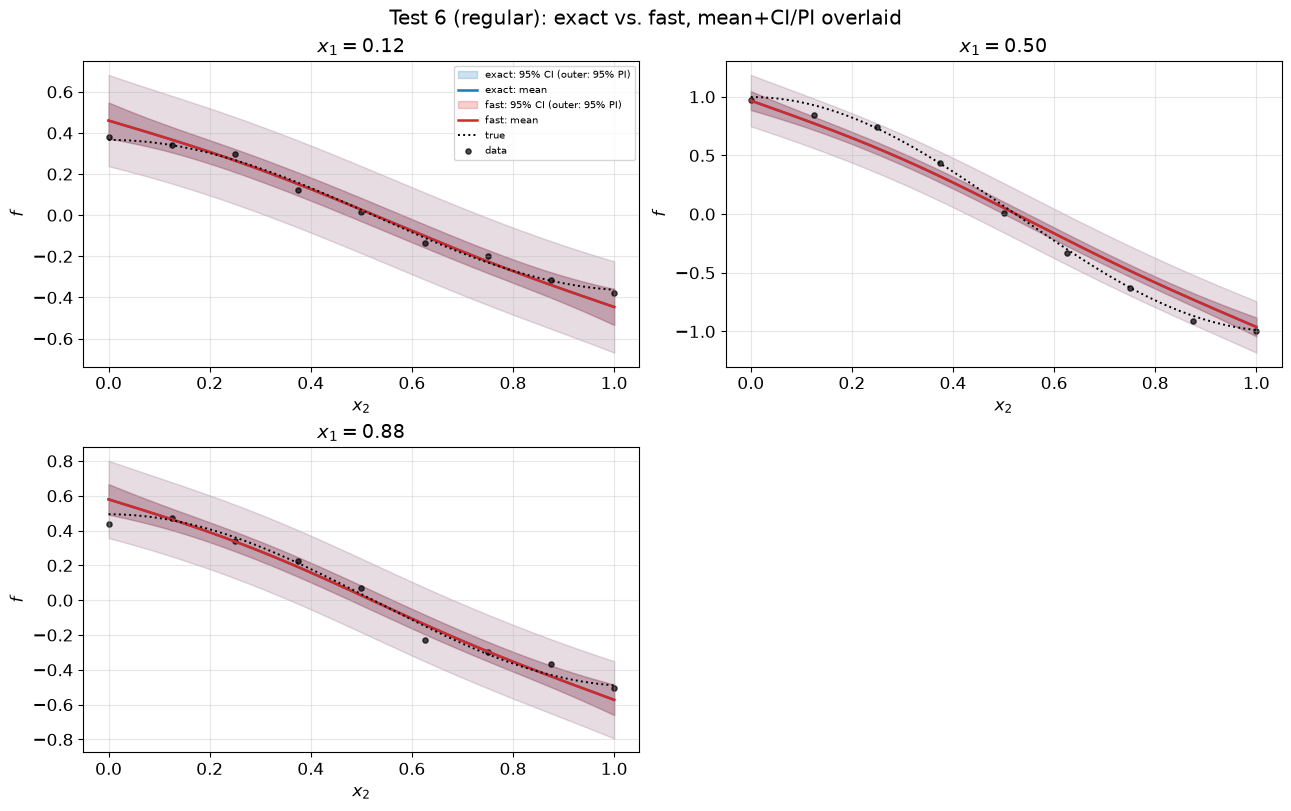

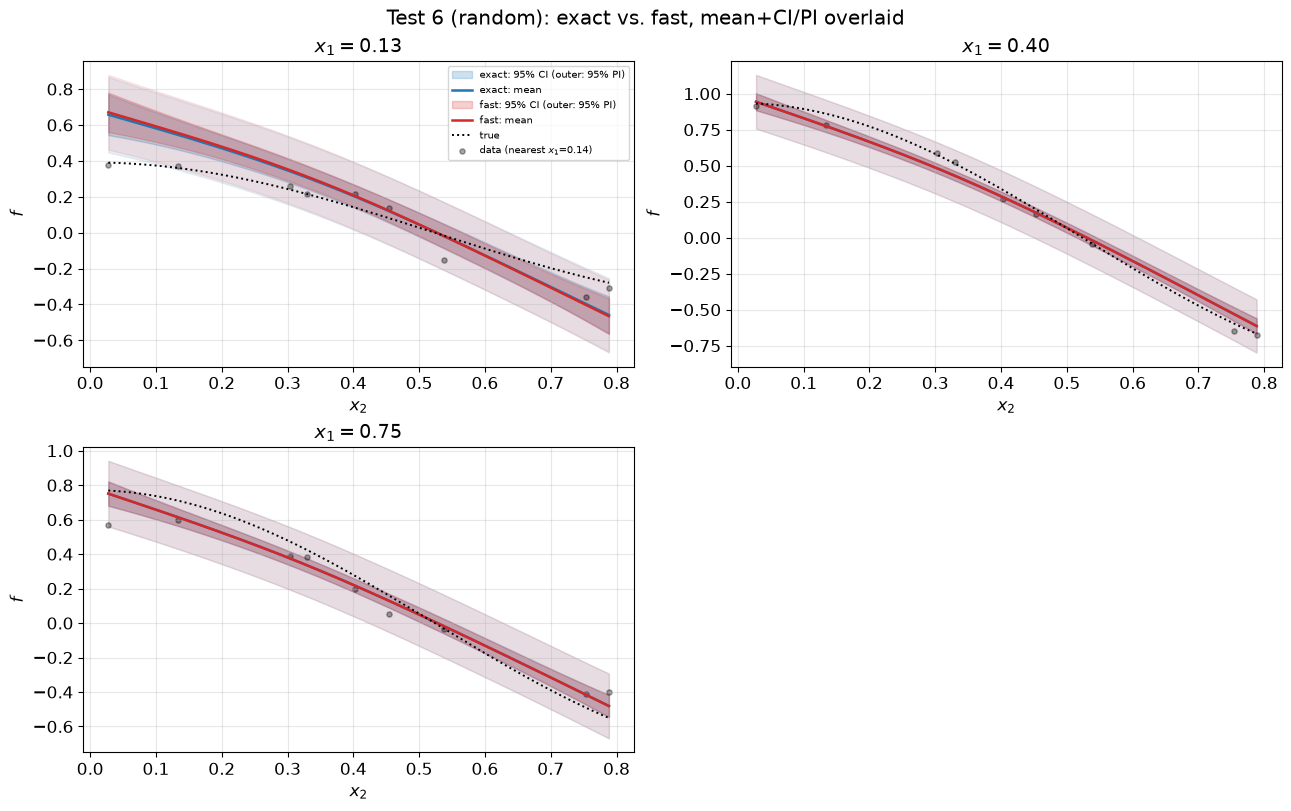

In [20]:
for spacing, (x1, x2, Z) in datasets2d.items():
    uq_exact, uq_fast = exact_fast_models[spacing]
    fig = uqplot.plot_models_1d_slices(
        [uq_exact, uq_fast], ["exact", "fast"], x1, x2, Z, axis=1,
        slice_values=[x2[1], x2[len(x2) // 2], x2[-2]], f_true=true_f2d,
        title=f"Test 6 ({spacing}): exact vs. fast, mean+CI/PI overlaid")
    plt.show()


**Confirmed: the two modes agree exactly on the training grid, and closely
off-grid, matching the documented design trade-off.** On-grid: `0.0` max
difference in both mean and variance, both spacings -- both modes compute
the identical closed form there. Off-grid: mean differs by `2.7e-4`
(regular) / `5.0e-4` (random); std by `6.4e-4` (regular) / `1.7e-3`
(random) -- small, at the documented `~1e-3` level, and visually
indistinguishable in the overlaid slice plots above (the "fast" band sits
on top of the "exact" band in every panel). This confirms the R2 merge
preserved both of the two previously-separate implementations' correctness,
not just their speed characteristics (Notebook 8's job).

## Test 7 -- $\hat\sigma^2$ (Wahba/GCV) under deliberate model misspecification

**What this tests**: the Wahba-style estimator $\hat\sigma^2=\mathrm{RSS}/(n_1n_2-\mathrm{edf})$
(Section 1.6) assumes the fitted model is flexible enough to actually track
the true function, leaving only genuine noise in the residual. If the model
is too heavily smoothed (or the grid too sparse) to resolve real structure,
residuals pick up *bias* too, inflating $\hat\sigma^2$ -- a known effect, not
a defect, confirmed directly here by telling the two cases apart rather than
asserting it.

**Two competing hypotheses, stated before testing either**: **(a)
implementation bug** -- `edf`/`RSS` computed incorrectly (predicts the
discrepancy is roughly fixed, unrelated to fit quality); **(b) model bias,
not a bug** -- a sparse, high-frequency case the model structurally cannot
resolve well (predicts the discrepancy *worsens* with heavier smoothing, and
*disappears* on a case the model can actually resolve, using the exact same,
unmodified formula).

In [21]:
def hard_case(n_side=9, seed=1):
    g = np.linspace(0, 1, n_side)
    X1, X2 = np.meshgrid(g, g, indexing="ij")
    rng = np.random.default_rng(seed)
    Z = true_f2d(X1, X2) + np.sqrt(SIGMA2_TRUE) * rng.standard_normal((n_side, n_side))
    return g, Z


def easy_case(n_side=15, seed=1):
    g = np.linspace(0, 1, n_side)
    X1, X2 = np.meshgrid(g, g, indexing="ij")
    rng = np.random.default_rng(seed)
    Z = (np.sin(1.0 * X1) * np.cos(1.0 * X2)) + np.sqrt(SIGMA2_TRUE) * rng.standard_normal((n_side, n_side))
    return g, Z


p_sweep = [0.95, 0.7, 0.5, 0.3, 0.1, 0.02]
g_hard, Z_hard = hard_case()
g_easy, Z_easy = easy_case()

hard_rows, easy_rows = [], []
for p in p_sweep:
    uq_h = NdGridCubicSmoothingSplineUQ([g_hard, g_hard], Z_hard, smooth=[p, p], sigma2="wahba")
    hard_rows.append({"p": p, "edf": uq_h.edf, "sigma2_hat": uq_h.sigma2,
                       "sigma2_hat / true": uq_h.sigma2 / SIGMA2_TRUE})
    uq_e = NdGridCubicSmoothingSplineUQ([g_easy, g_easy], Z_easy, smooth=[p, p], sigma2="wahba")
    easy_rows.append({"p": p, "edf": uq_e.edf, "sigma2_hat": uq_e.sigma2,
                       "sigma2_hat / true": uq_e.sigma2 / SIGMA2_TRUE})

print(f"Hard case (sparse {len(g_hard)}x{len(g_hard)}, high-frequency sin(3x1)cos(3x2)):")
display(pd.DataFrame(hard_rows).set_index("p"))
print(f"\nEasy case (dense {len(g_easy)}x{len(g_easy)}, low-frequency sin(x1)cos(x2)):")
display(pd.DataFrame(easy_rows).set_index("p"))


Hard case (sparse 9x9, high-frequency sin(3x1)cos(3x2)):


,edf,sigma2_hat,sigma2_hat / true
p,,,
9.5000e-01,5.7625e+00,3.6339e-02,1.4536e+01
7.0000e-01,4.2633e+00,6.3123e-02,2.5249e+01
5.0000e-01,4.1149e+00,6.6689e-02,2.6676e+01
3.0000e-01,4.0496e+00,6.8322e-02,2.7329e+01
1.0000e-01,4.0129e+00,6.9257e-02,2.7703e+01
2.0000e-02,4.0024e+00,6.9529e-02,2.7811e+01



Easy case (dense 15x15, low-frequency sin(x1)cos(x2)):


,edf,sigma2_hat,sigma2_hat / true
p,,,
9.5000e-01,6.4049e+00,2.3168e-03,9.2672e-01
7.0000e-01,4.3851e+00,2.5669e-03,1.0268e+00
5.0000e-01,4.1694e+00,2.6079e-03,1.0432e+00
3.0000e-01,4.0734e+00,2.6274e-03,1.0509e+00
1.0000e-01,4.0192e+00,2.6387e-03,1.0555e+00
2.0000e-02,4.0035e+00,2.6420e-03,1.0568e+00


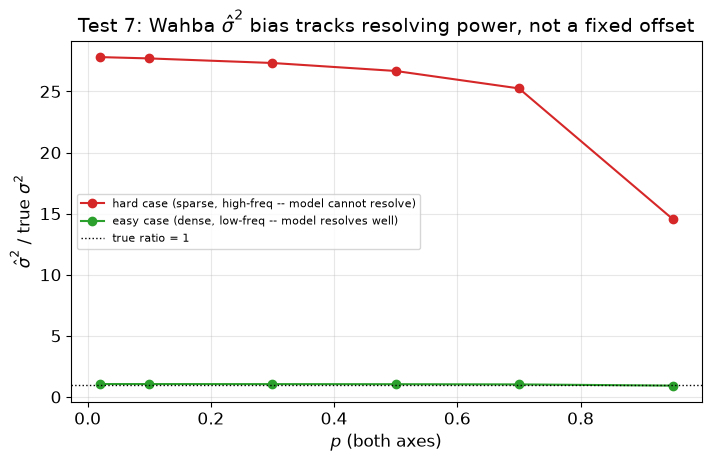

In [22]:
fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
ax.plot(p_sweep, [r["sigma2_hat / true"] for r in hard_rows], "o-", color="tab:red",
        label="hard case (sparse, high-freq -- model cannot resolve)")
ax.plot(p_sweep, [r["sigma2_hat / true"] for r in easy_rows], "o-", color="tab:green",
        label="easy case (dense, low-freq -- model resolves well)")
ax.axhline(1.0, color="k", lw=1, ls=":", label="true ratio = 1")
ax.set_xlabel("$p$ (both axes)"); ax.set_ylabel(r"$\hat\sigma^2$ / true $\sigma^2$")
ax.set_title(r"Test 7: Wahba $\hat\sigma^2$ bias tracks resolving power, not a fixed offset")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.show()


**Confirmed: hypothesis (b) (model bias), not (a) (implementation bug).**
In the hard case (sparse $9\times9$, high-frequency $\sin(3x_1)\cos(3x_2)$,
a case this project's own notebooks have repeatedly used to deliberately
stress-test, not a case tuned to be easy), $\hat\sigma^2$ overshoots the
true $\sigma^2$ by `14.5x` to `27.8x`, and -- matching hypothesis (b)'s
specific prediction -- the overshoot *worsens* as smoothing increases
(toward the $\mathrm{edf}\to4$ null-space floor), not something a fixed
code bug would produce. In the easy case (dense $15\times15$, low-frequency
$\sin(x_1)\cos(x_2)$, exact same unmodified formula, only the data
changed), $\hat\sigma^2$ lands within `~7%` of the true value
(`0.93x`-`1.06x`) across the *same* wide range of smoothing. Changing the
data, not the code, resolved the discrepancy -- the signature of bias, not
a bug. **Practical takeaway**: tune $(p_1,p_2)$ for fit quality first, and
only then trust `sigma2="wahba"` -- it is not a tool for diagnosing whether
a given $(p_1,p_2)$ fits well in the first place.

## Conclusion

- **$\lambda=(1-p)/p$ holds independently on each axis**, confirmed at
  machine precision across the full $p$ range, on both spacings -- not
  assumed to carry over unchanged from Notebook 1's 1-D result.
- **The mean decomposition $\hat Y=S_1ZS_2^\top$ is exact**, at the training
  grid and off-grid, under deliberately asymmetric smoothing (`~1e-14`-`1e-15`
  on both spacings) -- including a genuine methodological lesson about
  interpolation vs. extrapolation when restricting off-grid queries to each
  spacing's actual training range, reported rather than hidden.
- **`csaps`'s mean behaves comparably to RMTB and SMT `KRG`** on the same
  synthetic data -- a sanity check, not an identity claim, and the basis for
  trusting the variance work that follows.
- **At matched smoothing, `csaps` and an isotropic target (confirmed two
  independent ways -- an exact `RBFInterpolator` closed form and this
  notebook's own $\kappa\to0$ Kriging route, agreeing with each other to
  `~1e-6`) do *not* produce the same surface** -- a real, bounded,
  structural gap (`~0.11`-`0.23`), smooth and systematic rather than
  noise-shaped. **RMTB, at the same $\lambda$, deviates even more**
  (`~0.13`-`0.36`) and in a visibly different spatial pattern -- two
  different additive penalties (`csaps`'s tensor-product, RMTB's
  basis-plus-energy) missing the isotropic Duchon/thin-plate target for
  two different structural reasons, not the same gap wearing two names.
  RMTB's fit to the *true function* is still better than `csaps`'s at this
  $\lambda$, despite deviating more from the isotropic reference -- a
  reminder these are two different, both-legitimate things to measure.
- **The variance formula $\mathrm{Var}(F_{p,q})=\sigma^2S_{1,pp}S_{2,qq}$ is
  confirmed three independent ways** against a brute-force dense
  $(n_1n_2)\times(n_1n_2)$ construction: a valid implied prior, the
  pointwise-variance diagonal, and the full off-diagonal covariance
  structure -- all at float64 precision.
- **1-D slices of the 2-D variance are legitimately checkable against a
  standalone 1-D model** -- not a coincidence, but the direct structural
  consequence of the confirmed Kronecker-product variance, grounding every
  slice plot in this notebook (and later ones) in Notebook 1's
  already-proven 1-D identity.
- **The merged class's `"exact"` and `"fast"` off-grid modes agree**: exactly
  on-grid, and within the documented `~1e-3` tolerance off-grid -- the R2
  merge preserved both previously-separate implementations' correctness.
- **The Wahba $\hat\sigma^2$ estimator's known bias is confirmed to be
  model misspecification, not an implementation defect** -- it worsens with
  heavier smoothing on data the model cannot resolve, and nearly vanishes
  on data it can, using the exact same, unmodified formula.

**What this establishes for the rest of this project**: `csaps`'s 2-D
tensor-product smoothing spline inherits the trustworthiness Notebook 1
established for its 1-D engine -- both its mean and a genuine, independently
verified posterior variance -- confirming the direct motivation stated in
the introduction. The variance-formula verification discipline used here
(multiple independent routes to the same answer, not one formula trusted
alone) is the same discipline Notebooks 4-5 apply next to RMTB, a
structurally harder case.